# Week 3: Healthcare Operations, Statistical Investigation & Insight Discovery

**AnalystLab Africa · Data Science Internship** · **Author:** Molemi Molokoane

**Dataset:** healthcare dataset pack supplied by AnalystLab Africa (encounters, procedures, patients, payers, organizations, data dictionary). The records cover one hospital, Massachusetts General Hospital, from January 2011 to February 2022. Patient names in the pack end in generated digit sequences, and the field descriptions match the documentation of [Synthea](https://github.com/synthetichealth/synthea), MITRE's open-source synthetic patient generator, so the data appears to be **synthetic**. It is still treated as if it were real patient data.

**Research question:** *How do recorded total claim costs vary across encounter classes, and is encounter duration associated with cost?*

### Workflow
1. Business understanding and success criteria
2. Data inspection
3. Data preparation
4. Exploratory data analysis
5. Hypothesis 1: claim cost differs across encounter classes
6. Hypothesis 2: longer encounters cost more within a class
7. Validation
8. Limitations
9. Findings and recommendations

## 0. Setup

Runs in Google Colab or locally. The raw data pack is **not** stored in the public GitHub repository because `patients.csv` contains names and addresses, so in a fresh Colab session the setup cell asks you to upload the six CSV files.

In [3]:
# Core libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter, NullFormatter, PercentFormatter
from scipy import stats

# Display and plotting defaults
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

RANDOM_STATE = 42  # fixed seed so the bootstrap intervals are identical on every run

# Paths: raw files in Data/, charts in Visualizations/, aggregate result tables in Outputs/
DATA_DIR, VIZ_DIR, OUT_DIR = "Data", "Visualizations", "Outputs"
for folder in (DATA_DIR, VIZ_DIR, OUT_DIR):
    os.makedirs(folder, exist_ok=True)

# Encounter classes in a fixed order (largest to smallest), used by every table and chart
CLASS_ORDER = ["ambulatory", "outpatient", "urgentcare", "emergency", "wellness", "inpatient"]

# Colours: one colour for single-series charts, a fixed categorical order for multi-series charts
BAR_COLOR = "#2a78d6"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK = "#0b0b0b"
dollars = FuncFormatter(lambda v, _: f"${v:,.0f}")
plain = FuncFormatter(lambda v, _: f"{v:g}")

def save_fig(fig, name):
    # Save a chart to Visualizations/ and display it
    fig.savefig(os.path.join(VIZ_DIR, name), bbox_inches="tight", dpi=150)
    plt.show()

In [4]:
# Make sure the data pack is available; in Colab, upload it if it is not
REQUIRED_FILES = ["encounters.csv", "procedures.csv", "patients.csv", "payers.csv",
                  "organizations.csv", "data_dictionary.csv"]
missing_files = [f for f in REQUIRED_FILES if not os.path.exists(os.path.join(DATA_DIR, f))]

if missing_files:
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(f"Copy these files into {DATA_DIR}/ and rerun: {missing_files}")
    print("Select these files in the upload dialog:", missing_files)
    for name, content in files.upload().items():
        with open(os.path.join(DATA_DIR, name), "wb") as fh:
            fh.write(content)
    missing_files = [f for f in REQUIRED_FILES if not os.path.exists(os.path.join(DATA_DIR, f))]
    assert not missing_files, f"Still missing: {missing_files}"

print("All data files present.")

Select these files in the upload dialog: ['encounters.csv', 'data_dictionary.csv']


Saving data_dictionary.csv to data_dictionary.csv
Saving encounters.csv to encounters.csv
All data files present.


## 1. Business Understanding

**The challenge.** The hospital wants to understand where its encounter costs come from. Claim costs are recorded for every encounter, but nobody has established how much they differ between types of care (ambulatory, emergency, inpatient and so on), or whether longer encounters are reliably more expensive. Without that, budgets and cost reviews rely on averages that may be dominated by a handful of very expensive encounters.

- **Problem investigated:** how recorded total claim costs vary across encounter classes, and whether encounter duration is associated with claim cost within a class.
- **Why it matters:** encounter class is known as soon as a patient arrives, and duration is something operations teams actively manage (length of stay, clinic slot length). If cost differs strongly by class, budgets and cost reviews should be set per class. If duration tracks cost, managing time is also a lever on cost; if it does not, cost drivers lie elsewhere (procedures, medications).
- **Intended user:** hospital operations and finance managers (cost review, budgeting, capacity planning). They are not statisticians, so every result is also stated in plain language.
- **Decisions supported:** (1) whether cost targets and reviews should be set per encounter class rather than hospital-wide; (2) whether encounter duration is a useful proxy for cost when planning capacity and budgets.
- **Limitations of the evidence:**
  - One hospital only, so results cannot be compared across organisations or generalised.
  - The data appears to be synthetic, so patterns reflect the generator's rules as well as real-world behaviour.
  - `TOTAL_CLAIM_COST` is a **recorded claim amount**, not the hospital's actual cost of delivering care.
  - Medication and immunisation line items are included in the total but are not supplied as separate tables, so part of the cost cannot be explained.
  - There is no clinical severity information, so differences between classes cannot be attributed to how sick patients were.
  - Many encounters come from a small number of patients, so encounters are not independent observations.

**Variables required**

| Variable | Source | Role |
|---|---|---|
| `TOTAL_CLAIM_COST` | encounters | outcome |
| `ENCOUNTERCLASS` | encounters | grouping variable (H1) |
| `START`, `STOP` → duration in hours | encounters | explanatory variable (H2) |
| `PATIENT` | encounters | cluster identifier for repeated records |
| `BASE_ENCOUNTER_COST`, procedure `BASE_COST` | encounters, procedures | explain what makes up the total |
| `PAYER` → payer group | encounters, payers | potential confounder |
| `BIRTHDATE` → age at encounter | patients | potential confounder |

### Success criteria
The work is successful if:
1. **Independent reconciliation:** encounter counts, median claim cost per class and the number of encounters over 24 hours, recalculated with a separate script that does not use pandas, match the notebook exactly.
2. **Repeated records handled:** every hypothesis test is run at the encounter level *and* with one value per patient (or a patient-level bootstrap), and a conclusion is only stated when both agree.
3. **Effect sizes, not just p-values:** every hypothesis reports an effect size with a 95% confidence interval from a bootstrap that resamples patients.
4. **Privacy:** no names, addresses or other identifying patient fields appear in any printed output, chart or exported file (checked automatically at the end of the notebook).
5. **Reproducibility:** the notebook runs top to bottom in a fresh Colab session with identical results, and the README explains how to reproduce it.

## 2. Data Inspection

### 2.1 Load the files
`utf-8-sig` strips the byte-order mark that prefixes the first column name in every file.

In [5]:
def read(name):
    return pd.read_csv(os.path.join(DATA_DIR, f"{name}.csv"), encoding="utf-8-sig")

encounters_raw = read("encounters")
procedures_raw = read("procedures")
patients_raw = read("patients")
payers = read("payers")
organizations = read("organizations")
dictionary = read("data_dictionary")

tables = {"encounters": encounters_raw, "procedures": procedures_raw, "patients": patients_raw,
          "payers": payers, "organizations": organizations}
shape_summary = pd.DataFrame({name: {"rows": df.shape[0], "columns": df.shape[1]}
                              for name, df in tables.items()}).T
shape_summary

,rows,columns
encounters,27891,14
procedures,47701,9
patients,974,20
payers,10,7
organizations,1,8


### 2.2 Structure and data types
Patient rows are never displayed, only the column types. The encounter preview leaves out the patient key, which is not needed to understand the table.

In [6]:
encounters_raw.drop(columns=["PATIENT"]).head()

,Id,START,STOP,ORGANIZATION,PAYER,ENCOUNTERCLASS,CODE,DESCRIPTION,BASE_ENCOUNTER_COST,TOTAL_CLAIM_COST,PAYER_COVERAGE,REASONCODE,REASONDESCRIPTION
0,32c84703-2481-49cd-d571-3899d5820253,2011-01-02T09:26:36Z,2011-01-02T12:58:36Z,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,ambulatory,185347001,Encounter for problem (procedure),85.55,"1,018.02",0.00,NaN,NaN
1,c98059da-320a-c0a6-fced-c8815f3e3f39,2011-01-03T05:44:39Z,2011-01-03T06:01:42Z,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,outpatient,308335008,Patient encounter procedure,142.58,"2,619.36",0.00,NaN,NaN
2,4ad28a3a-2479-782b-f29c-d5b3f41a001e,2011-01-03T14:32:11Z,2011-01-03T14:47:11Z,d78e84ec-30aa-3bba-a33a-f29a3a454662,7caa7254-5050-3b5e-9eae-bd5ea30e809c,outpatient,185349003,Encounter for check up (procedure),85.55,461.59,305.27,NaN,NaN
3,c3f4da61-e4b4-21d5-587a-fbc89943bc19,2011-01-03T16:24:45Z,2011-01-03T16:39:45Z,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,wellness,162673000,General examination of patient (procedure),136.80,"1,784.24",0.00,NaN,NaN
4,a9183b4f-2572-72ea-54c2-b3cd038b4be7,2011-01-03T17:36:53Z,2011-01-03T17:51:53Z,d78e84ec-30aa-3bba-a33a-f29a3a454662,42c4fca7-f8a9-3cd1-982a-dd9751bf3e2a,ambulatory,390906007,Follow-up encounter,85.55,234.72,0.00,"55,822,004.00",Hyperlipidemia


In [7]:
for name, df in tables.items():
    print(f"--- {name}")
    print(df.dtypes.to_string(), "\n")

--- encounters
Id                      object
START                   object
STOP                    object
PATIENT                 object
ORGANIZATION            object
PAYER                   object
ENCOUNTERCLASS          object
CODE                     int64
DESCRIPTION             object
BASE_ENCOUNTER_COST    float64
TOTAL_CLAIM_COST       float64
PAYER_COVERAGE         float64
REASONCODE             float64
REASONDESCRIPTION       object 

--- procedures
START                 object
STOP                  object
PATIENT               object
ENCOUNTER             object
CODE                   int64
DESCRIPTION           object
BASE_COST              int64
REASONCODE           float64
REASONDESCRIPTION     object 

--- patients
Id             object
BIRTHDATE      object
DEATHDATE      object
PREFIX         object
FIRST          object
LAST           object
SUFFIX         object
MAIDEN         object
MARITAL        object
RACE           object
ETHNICITY      object
GENDER         o

Dates (`START`, `STOP`, `BIRTHDATE`, `DEATHDATE`) are read as text and must be converted. The cost columns are already numeric. The IDs are UUID strings.

### 2.3 Missing values

In [8]:
missing_rows = []
for name, df in tables.items():
    for col in df.columns:
        n = df[col].isna().sum()
        if n:
            missing_rows.append({"table": name, "column": col, "missing": n,
                                 "pct_missing": round(100 * n / len(df), 1)})
missing_summary = pd.DataFrame(missing_rows)
missing_summary

,table,column,missing,pct_missing
0,encounters,REASONCODE,19541,70.10
1,encounters,REASONDESCRIPTION,19541,70.10
2,procedures,REASONCODE,36945,77.50
3,procedures,REASONDESCRIPTION,36945,77.50
4,patients,DEATHDATE,820,84.20
5,patients,SUFFIX,953,97.80
6,patients,MAIDEN,588,60.40
7,patients,MARITAL,1,0.10
8,patients,ZIP,142,14.60
9,payers,ADDRESS,1,10.00


None of the missing values affect the research question. Each one has a structural meaning, so **nothing is imputed**:
- `REASONCODE` / `REASONDESCRIPTION` (70% of encounters, 78% of procedures) are only filled in when the encounter targeted a specific condition, according to the data dictionary.
- `DEATHDATE` is blank for patients who are alive. `SUFFIX` and `MAIDEN` only apply to some people. `MARITAL` and `ZIP` are not used.
- The `NO_INSURANCE` payer has no address because it is not an organisation.

Every variable the analysis uses (class, costs, start/stop, patient, payer, birth date) is complete.

### 2.4 Data dictionary vs actual columns
The brief warns that not every documented field is present. Field names are compared after upper-casing and replacing spaces with underscores.

In [9]:
dictionary_fields = (dictionary.dropna(subset=["Field"])
                     .assign(field=lambda d: d["Field"].str.upper().str.replace(" ", "_")))
dict_check = []
for name, df in tables.items():
    documented = set(dictionary_fields.loc[dictionary_fields["Table"] == name, "field"])
    actual = {c.upper() for c in df.columns}
    dict_check.append({"table": name,
                       "documented but absent": sorted(documented - actual),
                       "present but undocumented": sorted(actual - documented)})
pd.DataFrame(dict_check)

,table,documented but absent,present but undocumented
0,encounters,[],[]
1,procedures,[],[]
2,patients,"[FIPS_COUNTY_CODE, MIDDLE]",[]
3,payers,[],[]
4,organizations,[],[]


`patients.csv` is missing `MIDDLE` and `FIPS County Code`. Neither is needed here. All encounter and procedure fields match the dictionary.

### 2.5 Privacy: drop identifying patient fields
`patients.csv` contains names, addresses, birthplace and coordinates. The analysis only needs the patient key, birth date (to derive age), death date and gender. Everything else is dropped now and never printed, charted or exported.

In [10]:
PATIENT_KEEP = ["Id", "BIRTHDATE", "DEATHDATE", "GENDER"]
print("Dropped identifying columns:", [c for c in patients_raw.columns if c not in PATIENT_KEEP])
patients = patients_raw[PATIENT_KEEP].copy()
del patients_raw
tables["patients"] = patients

Dropped identifying columns: ['PREFIX', 'FIRST', 'LAST', 'SUFFIX', 'MAIDEN', 'MARITAL', 'RACE', 'ETHNICITY', 'BIRTHPLACE', 'ADDRESS', 'CITY', 'STATE', 'COUNTY', 'ZIP', 'LAT', 'LON']


### 2.6 Duplicates
Exact duplicate rows and duplicate primary keys are checked first. Then two near-duplicate patterns are checked: encounters for the same patient starting at the same moment, and the same procedure code recorded twice within one encounter.

In [11]:
duplicate_summary = pd.DataFrame({
    "exact duplicate rows": {n: df.duplicated().sum() for n, df in tables.items()},
    "duplicate Ids": {n: df["Id"].duplicated().sum() if "Id" in df else np.nan for n, df in tables.items()},
})
display(duplicate_summary)

same_start = encounters_raw.duplicated(["PATIENT", "START"], keep=False)
same_start_class = encounters_raw.duplicated(["PATIENT", "ENCOUNTERCLASS", "START"], keep=False)
same_start_full = encounters_raw.duplicated(
    ["PATIENT", "START", "STOP", "ENCOUNTERCLASS", "CODE", "TOTAL_CLAIM_COST"], keep=False)
repeated_procedures = procedures_raw.duplicated(["ENCOUNTER", "CODE", "START"], keep=False)

print(f"Encounters sharing patient + start time:              {same_start.sum():,}")
print(f"  ... and the same class:                              {same_start_class.sum():,}")
print(f"  ... and identical stop, code and claim cost:         {same_start_full.sum():,}")
print(f"Procedures repeated within an encounter (same code+start): {repeated_procedures.sum():,}")

,exact duplicate rows,duplicate Ids
encounters,0,0.00
procedures,0,NaN
patients,0,0.00
payers,0,0.00
organizations,0,0.00


Encounters sharing patient + start time:              643
  ... and the same class:                              54
  ... and identical stop, code and claim cost:         0
Procedures repeated within an encounter (same code+start): 0


In [12]:
# What do the same-start encounters look like? (no patient identifiers shown)
encounters_raw[same_start].groupby(["ENCOUNTERCLASS", "DESCRIPTION"]).size().sort_values(ascending=False).head(10)

,,0
ENCOUNTERCLASS,DESCRIPTION,
ambulatory,Postoperative follow-up visit (procedure),179
inpatient,Screening surveillance (regime/therapy),179
outpatient,Consultation for treatment,40
ambulatory,Postnatal visit,39
wellness,General examination of patient (procedure),35
ambulatory,Encounter for problem,27
outpatient,Administration of vaccine to produce active immunity (procedure),23
inpatient,Admission to intensive care unit (procedure),17
emergency,Encounter for Problem,17


There are no exact duplicates and no repeated primary keys. 643 encounters share a patient and start time with another encounter, but **none** also share the stop time, code and claim cost. They are different types of care booked at the same moment, for example a postoperative follow-up alongside an inpatient screening. They are therefore treated as genuine, separate encounters and **not removed**.

### 2.7 Relationships between tables
`encounters` is the central table: `PATIENT` → `patients.Id`, `PAYER` → `payers.Id`, `ORGANIZATION` → `organizations.Id`, and `procedures.ENCOUNTER` → `encounters.Id` (one encounter, zero or more procedures).

In [13]:
key_checks = [
    ("encounters.PATIENT → patients.Id", encounters_raw["PATIENT"], patients["Id"]),
    ("encounters.PAYER → payers.Id", encounters_raw["PAYER"], payers["Id"]),
    ("encounters.ORGANIZATION → organizations.Id", encounters_raw["ORGANIZATION"], organizations["Id"]),
    ("procedures.ENCOUNTER → encounters.Id", procedures_raw["ENCOUNTER"], encounters_raw["Id"]),
    ("procedures.PATIENT → patients.Id", procedures_raw["PATIENT"], patients["Id"]),
]
pd.DataFrame([{"relationship": label, "rows": len(fk), "unmatched": (~fk.isin(pk)).sum()}
              for label, fk, pk in key_checks])

,relationship,rows,unmatched
0,encounters.PATIENT → patients.Id,27891,0
1,encounters.PAYER → payers.Id,27891,0
2,encounters.ORGANIZATION → organizations.Id,27891,0
3,procedures.ENCOUNTER → encounters.Id,47701,0
4,procedures.PATIENT → patients.Id,47701,0


In [14]:
print("Organisations in the data:", organizations["NAME"].tolist())
print("Encounters with at least one procedure:",
      f"{encounters_raw['Id'].isin(procedures_raw['ENCOUNTER']).sum():,} of {len(encounters_raw):,}")

Organisations in the data: ['MASSACHUSETTS GENERAL HOSPITAL']
Encounters with at least one procedure: 14,670 of 27,891


All foreign keys match: there are no orphan records. Because there is **only one organisation**, hospital-level comparisons are impossible. Only about half of encounters have a procedure, so procedure cost can only partly explain claim cost.

## 3. Data Preparation

No rows are deleted. Problem records are **flagged**, and each analysis states which records it uses, so every exclusion is visible and reversible.

### 3.1 Dates and duration

In [15]:
enc = encounters_raw.copy()
ISO_UTC = "%Y-%m-%dT%H:%M:%SZ"
for col in ["START", "STOP"]:
    enc[col] = pd.to_datetime(enc[col], format=ISO_UTC, utc=True, errors="coerce")

enc["duration_h"] = (enc["STOP"] - enc["START"]).dt.total_seconds() / 3600

print("Unparseable START / STOP:", enc["START"].isna().sum(), "/", enc["STOP"].isna().sum())
print("STOP before START:       ", (enc["duration_h"] < 0).sum())
print("Zero-length encounters:  ", (enc["duration_h"] == 0).sum())
print("Date range:              ", enc["START"].min().date(), "to", enc["START"].max().date())
print("Encounters over 24 hours:", (enc["duration_h"] > 24).sum())

Unparseable START / STOP: 0 / 0
STOP before START:        0
Zero-length encounters:   0
Date range:               2011-01-02 to 2022-02-05
Encounters over 24 hours: 75


In [16]:
enc["year"] = enc["START"].dt.year
enc["quarter"] = enc["START"].dt.to_period("Q").astype(str)
enc.groupby(enc["START"].dt.strftime("%Y-%m")).size().tail(6)

/tmp/ipykernel_5635/156360634.py:2: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  enc["quarter"] = enc["START"].dt.to_period("Q").astype(str)


,0
START,
2021-09,246
2021-10,225
2021-11,267
2021-12,231
2022-01,219
2022-02,1


All timestamps parse and none run backwards. The data stops on **5 February 2022** (one encounter in February), so **2022 is a partial year** and must not be compared with full years.

### 3.2 Implausible durations

In [17]:
long_enc = enc[enc["duration_h"] > 24]
print(long_enc["ENCOUNTERCLASS"].value_counts().to_string(), "\n")
(long_enc[long_enc["ENCOUNTERCLASS"] != "inpatient"]
 .assign(start_date=lambda d: d["START"].dt.date, duration_days=lambda d: d["duration_h"] / 24)
 [["ENCOUNTERCLASS", "DESCRIPTION", "start_date", "duration_days", "TOTAL_CLAIM_COST"]]
 .sort_values("duration_days", ascending=False))

ENCOUNTERCLASS
inpatient     58
outpatient     7
emergency      5
ambulatory     5 



,ENCOUNTERCLASS,DESCRIPTION,start_date,duration_days,TOTAL_CLAIM_COST
9704,ambulatory,Follow-up encounter (procedure),2014-12-17,"1,872.08",85.55
7735,ambulatory,Follow-up encounter (procedure),2014-03-27,"1,812.62",85.55
7805,ambulatory,Follow-up encounter (procedure),2014-04-02,455.64,85.55
6116,outpatient,Encounter for problem (procedure),2014-01-31,446.00,85.55
6371,outpatient,Encounter for problem (procedure),2014-02-06,348.00,85.55
6380,outpatient,Encounter for problem (procedure),2014-02-06,341.00,85.55
7832,ambulatory,Follow-up encounter (procedure),2014-04-04,301.63,85.55
6125,outpatient,Encounter for problem (procedure),2014-01-31,145.00,85.55
6138,outpatient,Encounter for problem (procedure),2014-01-31,68.00,85.55
6332,outpatient,Encounter for problem (procedure),2014-02-05,68.00,85.55


Inpatient stays longer than a day are expected. The 17 **non-inpatient** encounters above are not:
- **12 ambulatory/outpatient encounters, all from 2014 and all billed at the minimum $85.55,** apparently lasted from 27 days up to 5 years (1,872 days). These are clearly recording errors, most likely a wrong `STOP` date.
- **5 emergency encounters lasted 1 to 25 days.** One of them is the **single most expensive encounter in the data ($641,883)**. Its cost might be genuine even though its duration is not.

**Decision:** flag them as `duration_suspect`. They stay in the cost analysis (H1), because their cost and class are plausible, but are excluded from the duration analysis (H2).

In [18]:
enc["duration_suspect"] = (enc["duration_h"] > 24) & (enc["ENCOUNTERCLASS"] != "inpatient")
print("Flagged duration_suspect:", enc["duration_suspect"].sum())
print("Inpatient stays over 30 days:", ((enc["ENCOUNTERCLASS"] == "inpatient") & (enc["duration_h"] > 24 * 30)).sum())

Flagged duration_suspect: 17
Inpatient stays over 30 days: 2


### 3.3 How much does duration actually vary within each class?

In [19]:
def share_at_mode(s):
    return s.round(3).value_counts(normalize=True).iloc[0]

valid = enc[~enc["duration_suspect"]]
duration_profile = (valid.groupby("ENCOUNTERCLASS")["duration_h"]
                    .agg(distinct_values=lambda s: s.round(3).nunique(), median="median",
                         p95=lambda s: s.quantile(0.95), share_at_most_common_value=share_at_mode)
                    .reindex(CLASS_ORDER))
duration_profile

,distinct_values,median,p95,share_at_most_common_value
ENCOUNTERCLASS,,,,
ambulatory,802,0.25,3.53,0.63
outpatient,322,0.25,0.32,0.92
urgentcare,1,0.25,0.25,1.00
emergency,33,1.00,1.00,0.98
wellness,1,0.25,0.25,1.00
inpatient,59,24.00,24.63,0.95


**Wellness and urgent care encounters all last exactly 15 minutes**, and almost all other encounters sit on a single value too: 98% of emergency encounters last exactly 1 hour, 95% of inpatient stays last about 24 hours, and 92% of outpatient encounters last 15 minutes. Only ambulatory encounters vary much (63% at the most common value). Durations appear to come from fixed templates rather than real recorded times. A correlation needs variation, so H2 can only be tested in classes with more than one distinct duration, and the heavy ties must be kept in mind when reading the results.

In [20]:
VARIABLE_DURATION_CLASSES = [c for c in CLASS_ORDER if duration_profile.loc[c, "distinct_values"] > 1]
print("Classes usable for the duration analysis:", VARIABLE_DURATION_CLASSES)

Classes usable for the duration analysis: ['ambulatory', 'outpatient', 'emergency', 'inpatient']


### 3.4 What makes up the total claim cost?
Procedures are summed per encounter and joined to encounters. An encounter with no procedure rows genuinely had **zero** procedures, so filling those gaps with 0 is correct here (it is not imputation).

In [21]:
proc_per_enc = procedures_raw.groupby("ENCOUNTER").agg(n_procedures=("CODE", "size"),
                                                       procedure_cost=("BASE_COST", "sum"))
enc = enc.merge(proc_per_enc, left_on="Id", right_index=True, how="left")
enc[["n_procedures", "procedure_cost"]] = enc[["n_procedures", "procedure_cost"]].fillna(0)
enc["has_procedure"] = enc["n_procedures"] > 0

# "Equal" means equal to the cent. rtol=0 because np.isclose's default relative tolerance would let a
# $40,000 claim "match" while 40 cents off; atol is half a cent so 1-cent differences never sit on the boundary
base_plus_proc = np.isclose(enc["TOTAL_CLAIM_COST"], enc["BASE_ENCOUNTER_COST"] + enc["procedure_cost"], rtol=0, atol=0.005)
base_only = np.isclose(enc["TOTAL_CLAIM_COST"], enc["BASE_ENCOUNTER_COST"], rtol=0, atol=0.005)
one_cent_off = np.isclose(enc["TOTAL_CLAIM_COST"] - enc["BASE_ENCOUNTER_COST"] - enc["procedure_cost"], 0, rtol=0, atol=0.015) & ~base_plus_proc
print(f"Total = base cost only:                {base_only.mean():.1%}")
print(f"Total = base + procedure costs:        {base_plus_proc.mean():.1%}")
print(f"Off by exactly one cent:               {one_cent_off.sum()}")
print(f"Total below base cost:                 {(enc['TOTAL_CLAIM_COST'] < enc['BASE_ENCOUNTER_COST'] - 0.01).sum()}")
print("Distinct base encounter costs:", sorted(enc["BASE_ENCOUNTER_COST"].unique()))

Total = base cost only:                31.3%
Total = base + procedure costs:        30.3%
Off by exactly one cent:               124
Total below base cost:                 89
Distinct base encounter costs: [np.float64(85.55), np.float64(87.71), np.float64(136.8), np.float64(142.58), np.float64(146.18)]


Base encounter cost takes only five fixed values ($85.55–$146.18), so it carries almost no information. Total claim cost equals base plus procedure cost for only about 30% of encounters. The remainder includes line items, such as medications and immunisations, that are **not supplied** in this pack. That is a limitation for explaining *why* costs differ.

### 3.5 Zero-cost claims

In [22]:
zero_claim = enc["TOTAL_CLAIM_COST"] == 0
enc[zero_claim].groupby(["ENCOUNTERCLASS", "DESCRIPTION"]).size().sort_values(ascending=False)

ENCOUNTERCLASS  DESCRIPTION                                                           
wellness        Death Certification                                                       51
inpatient       Admission to hospice (procedure)                                          20
ambulatory      Follow-up encounter (procedure)                                            4
emergency       Emergency Room Admission                                                   4
inpatient       Admission to intensive care unit (procedure)                               3
                Periodic reevaluation and management of healthy individual (procedure)     3
                Encounter for symptom (procedure)                                          2
emergency       Encounter for problem                                                      1
                Emergency room admission (procedure)                                       1
dtype: int64

The $0 claims are dominated by **death certification** (wellness) and similar administrative encounters. Recording them as free is plausible, so they are kept. Charts on a log scale cannot show $0 and leave them out; this is noted on each chart.

### 3.6 Payer group and patient age (potential confounders)

In [23]:
enc["payer_name"] = enc["PAYER"].map(payers.set_index("Id")["NAME"])
PAYER_GROUPS = ["Medicare", "Medicaid / Dual", "Private", "No insurance"]
enc["payer_group"] = np.select(
    [enc["payer_name"].eq("Medicare"), enc["payer_name"].isin(["Medicaid", "Dual Eligible"]),
     enc["payer_name"].eq("NO_INSURANCE")],
    ["Medicare", "Medicaid / Dual", "No insurance"], default="Private")

birth = pd.to_datetime(patients.set_index("Id")["BIRTHDATE"], format="%Y-%m-%d", utc=True)
enc["age_at_encounter"] = (enc["START"] - enc["PATIENT"].map(birth)).dt.days / 365.25

print(enc["payer_group"].value_counts().to_string())
print("\nAge at encounter: min {:.1f}, median {:.1f}, max {:.1f}".format(
    enc["age_at_encounter"].min(), enc["age_at_encounter"].median(), enc["age_at_encounter"].max()))

payer_group
Medicare           11371
No insurance        8807
Private             5358
Medicaid / Dual     2355

Age at encounter: min 19.9, median 79.7, max 99.3


All patients are adults at the time of their encounters (youngest 19.9 years), and the **median age at encounter is about 80**. This is an elderly population, so results may not carry over to a general hospital population.

### 3.7 Same-start encounters

In [24]:
# Decision recorded after reviewing Section 2.6: same-start encounters have distinct IDs and are
# kept as separate encounters; fully identical ones (same stop, code and cost) are flagged.
enc["possible_double_entry"] = same_start_full.values
print("Flagged possible_double_entry:", enc["possible_double_entry"].sum())

Flagged possible_double_entry: 0


### 3.8 Data-quality summary

In [25]:
data_quality_summary = pd.DataFrame([
    ("Missing REASONCODE / REASONDESCRIPTION", f"{encounters_raw['REASONCODE'].isna().sum():,} encounters",
     "Structural (only set when a condition was targeted); not used, not imputed"),
    ("Dictionary fields absent from CSV", "patients: MIDDLE, FIPS County Code", "Not needed; documented"),
    ("Identifying patient fields", f"{len(PATIENT_KEEP)} of 20 patient columns kept",
     "Names, addresses, coordinates dropped on load"),
    ("Exact duplicates / duplicate IDs", "0 in every table", "None to remove"),
    ("Same patient + start time", f"{same_start.sum():,} encounters",
     "Distinct IDs, kept; fully identical ones flagged possible_double_entry"),
    ("Non-inpatient encounters over 24 h", f"{enc['duration_suspect'].sum()} encounters",
     "Flagged duration_suspect; kept for cost, excluded from duration analysis"),
    ("Template durations", "wellness and urgent care always 15 min",
     "Those classes excluded from the duration analysis"),
    ("Partial year", "2022 covers 1 Jan to 5 Feb only", "Excluded from year-on-year comparisons"),
    ("Zero total claim cost", f"{zero_claim.sum()} encounters", "Kept (mostly death certification)"),
    ("Total claim not explained by supplied tables", f"{1 - base_plus_proc.mean():.0%} of encounters",
     "Medication/immunisation line items not supplied; limitation"),
    ("Single organisation", "1 hospital", "No between-hospital comparison possible"),
    ("Repeated records", f"{enc['PATIENT'].nunique():,} patients, {len(enc):,} encounters",
     "Tests use patient-level values and patient bootstrap"),
], columns=["issue", "extent", "decision"])
data_quality_summary.to_csv(os.path.join(OUT_DIR, "data_quality_summary.csv"), index=False)
data_quality_summary

,issue,extent,decision
0,Missing REASONCODE / REASONDESCRIPTION,"19,541 encounters",Structural (only set when a condition was targ...
1,Dictionary fields absent from CSV,"patients: MIDDLE, FIPS County Code",Not needed; documented
2,Identifying patient fields,4 of 20 patient columns kept,"Names, addresses, coordinates dropped on load"
3,Exact duplicates / duplicate IDs,0 in every table,None to remove
4,Same patient + start time,643 encounters,"Distinct IDs, kept; fully identical ones flagg..."
5,Non-inpatient encounters over 24 h,17 encounters,"Flagged duration_suspect; kept for cost, exclu..."
6,Template durations,wellness and urgent care always 15 min,Those classes excluded from the duration analysis
7,Partial year,2022 covers 1 Jan to 5 Feb only,Excluded from year-on-year comparisons
8,Zero total claim cost,89 encounters,Kept (mostly death certification)
9,Total claim not explained by supplied tables,70% of encounters,Medication/immunisation line items not supplie...


## 4. Exploratory Data Analysis

### 4.1 Encounter volume by class

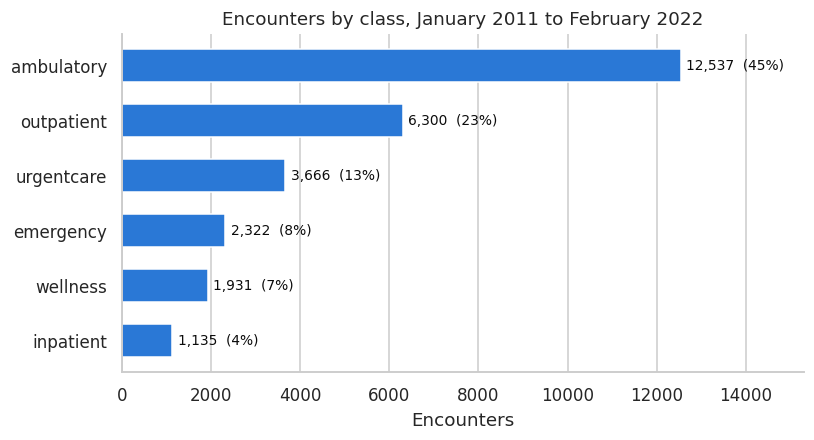

In [26]:
counts = enc["ENCOUNTERCLASS"].value_counts().reindex(CLASS_ORDER)
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(CLASS_ORDER[::-1], counts.values[::-1], color=BAR_COLOR, height=0.6)
for y, n in enumerate(counts.values[::-1]):
    ax.text(n + counts.max() * 0.01, y, f"{n:,}  ({n / len(enc):.0%})", va="center", fontsize=9, color=INK)
ax.set(xlabel="Encounters", xlim=(0, counts.max() * 1.22),
       title="Encounters by class, January 2011 to February 2022")
ax.grid(axis="y", visible=False)
save_fig(fig, "01_encounters_by_class.png")

Ambulatory and outpatient care make up **68% of all encounters**. Inpatient stays are only 4%. The groups are very unequal in size, so any comparison must not assume equal group sizes.

### 4.2 Distribution of total claim cost

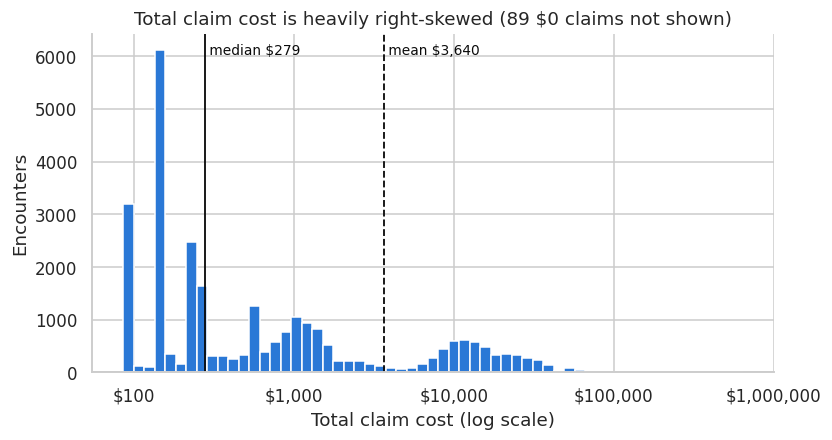

count    27,891.00
mean      3,639.68
std       9,205.60
min           0.00
25%         142.58
50%         278.58
75%       1,412.53
95%      20,785.89
99%      37,286.68
max     641,882.70
Skewness: 16.3


In [27]:
cost = enc["TOTAL_CLAIM_COST"]
positive = cost[cost > 0]
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(positive, bins=np.logspace(np.log10(positive.min()), np.log10(positive.max()), 60), color=BAR_COLOR)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(dollars)
for value, label, style in [(cost.median(), "median", "-"), (cost.mean(), "mean", "--")]:
    ax.axvline(value, color=INK, ls=style, lw=1.2)
    ax.text(value, ax.get_ylim()[1] * 0.97, f" {label} ${value:,.0f}", va="top", fontsize=9, color=INK)
ax.set(xlabel="Total claim cost (log scale)", ylabel="Encounters",
       title=f"Total claim cost is heavily right-skewed ({zero_claim.sum()} $0 claims not shown)")
save_fig(fig, "02_claim_cost_distribution.png")

print(cost.describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).to_string())
print(f"Skewness: {cost.skew():.1f}")

Claim cost is extremely right-skewed (skewness about 16). The **mean ($3,640) is 13 times the median ($279)**, and the single largest claim is $641,883. The distribution is also **bimodal**: a large group of cheap encounters between $86 and $300 (base cost with few or no line items), and a second hump around $10,000.

**Consequences:** the mean is a misleading "typical cost" here. The analysis reports medians and uses rank-based (non-parametric) methods rather than t-tests or ANOVA on raw costs.

### 4.3 Claim cost by encounter class

In [28]:
class_summary = (enc.groupby("ENCOUNTERCLASS")
                 .agg(encounters=("Id", "size"), patients=("PATIENT", "nunique"),
                      median_cost=("TOTAL_CLAIM_COST", "median"),
                      q1=("TOTAL_CLAIM_COST", lambda s: s.quantile(0.25)),
                      q3=("TOTAL_CLAIM_COST", lambda s: s.quantile(0.75)),
                      mean_cost=("TOTAL_CLAIM_COST", "mean"),
                      p95=("TOTAL_CLAIM_COST", lambda s: s.quantile(0.95)),
                      max_cost=("TOTAL_CLAIM_COST", "max"),
                      total_cost=("TOTAL_CLAIM_COST", "sum"),
                      pct_with_procedure=("has_procedure", "mean"),
                      median_age=("age_at_encounter", "median"))
                 .reindex(CLASS_ORDER))
class_summary["share_of_total_cost"] = class_summary["total_cost"] / class_summary["total_cost"].sum()
class_summary.to_csv(os.path.join(OUT_DIR, "class_cost_summary.csv"))
class_summary

,encounters,patients,median_cost,q1,q3,mean_cost,p95,max_cost,total_cost,pct_with_procedure,median_age,share_of_total_cost
ENCOUNTERCLASS,,,,,,,,,,,,
ambulatory,12537,695,573.98,142.58,"1,267.08","2,894.11","14,071.71","65,318.86","36,283,440.84",0.55,80.47,0.36
outpatient,6300,624,278.58,153.89,594.45,"2,237.30","12,973.98","43,321.62","14,094,967.12",0.53,70.38,0.14
urgentcare,3666,247,142.58,142.58,"8,921.39","6,369.16","32,378.40","47,998.67","23,349,349.96",0.28,83.21,0.23
emergency,2322,465,146.18,146.18,"4,288.38","4,629.65","25,894.47","641,882.70","10,750,051.53",0.31,84.24,0.11
wellness,1931,209,"1,231.44",853.37,"1,643.68","4,260.71","26,823.52","65,633.22","8,227,431.73",0.88,77.06,0.08
inpatient,1135,153,"2,355.59",313.96,"14,092.26","7,761.35","21,184.36","309,748.16","8,809,134.34",0.92,75.40,0.09


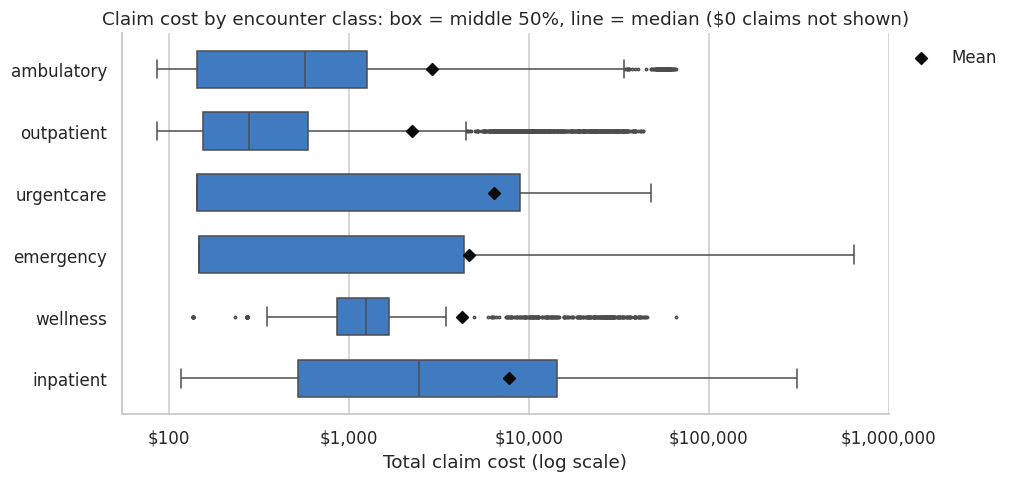

In [29]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=enc[enc["TOTAL_CLAIM_COST"] > 0], x="TOTAL_CLAIM_COST", y="ENCOUNTERCLASS",
            order=CLASS_ORDER, color=BAR_COLOR, log_scale=True, fliersize=1.5, width=0.6, ax=ax)
ax.scatter(class_summary["mean_cost"], range(len(CLASS_ORDER)), marker="D", s=30, color=INK, zorder=3, label="Mean")
ax.xaxis.set_major_formatter(dollars)
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False)
ax.set(xlabel="Total claim cost (log scale)", ylabel="",
       title="Claim cost by encounter class: box = middle 50%, line = median ($0 claims not shown)")
save_fig(fig, "03_claim_cost_by_class.png")

- **Inpatient** has the highest median claim ($2,356), followed by **wellness** ($1,231). Wellness costs are the most predictable, with a narrow middle 50%.
- **Urgent care and emergency** have the *lowest* medians ($143 and $146, essentially just the base cost), yet their **means are among the highest**. Most of these visits are cheap, but a large minority are very expensive: the upper quartile starts at $8,921 for urgent care.
- Urgent care is **13% of encounters but 23% of total claim cost**. Ambulatory, the largest class, carries the biggest share of total cost (36%).
- The classes differ in **shape**, not just level. This matters for H1: a rank test will detect "one class tends to cost more", not specifically "the medians differ".

### 4.4 Repeated records: encounters per patient

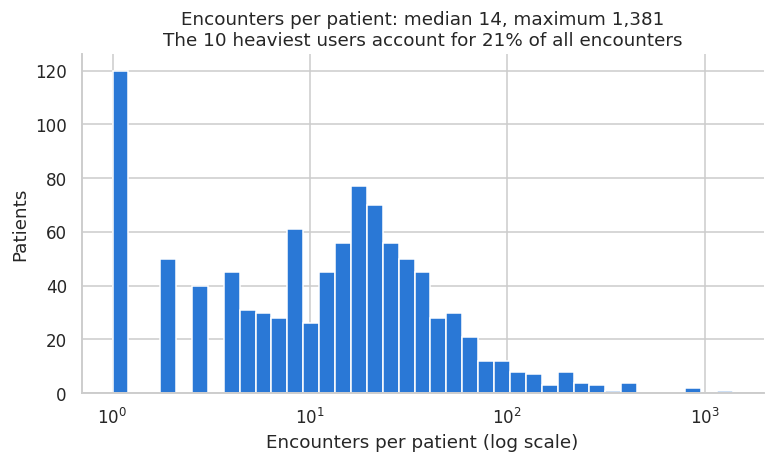

count     974.00
mean       28.64
std        73.04
min         1.00
25%         4.00
50%        14.00
75%        28.00
max     1,381.00


In [30]:
per_patient = enc.groupby("PATIENT").size()
top10_share = per_patient.nlargest(10).sum() / len(enc)
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(per_patient, bins=np.logspace(0, np.log10(per_patient.max()), 40), color=BAR_COLOR)
ax.set_xscale("log")
ax.set(xlabel="Encounters per patient (log scale)", ylabel="Patients",
       title=f"Encounters per patient: median {per_patient.median():.0f}, maximum {per_patient.max():,}\n"
             f"The 10 heaviest users account for {top10_share:.0%} of all encounters")
save_fig(fig, "04_encounters_per_patient.png")
print(per_patient.describe().to_string())

Encounters are **not independent**. A typical patient has 14 encounters, one patient has 1,381, and **the 10 heaviest users generate 21% of all encounters**. A test that treats the 27,891 encounters as independent observations would overstate the evidence and let a few patients dominate the result. The hypothesis tests therefore also use **one value per patient**, and confidence intervals come from a bootstrap that **resamples patients, not encounters**.

### 4.5 Duration by class

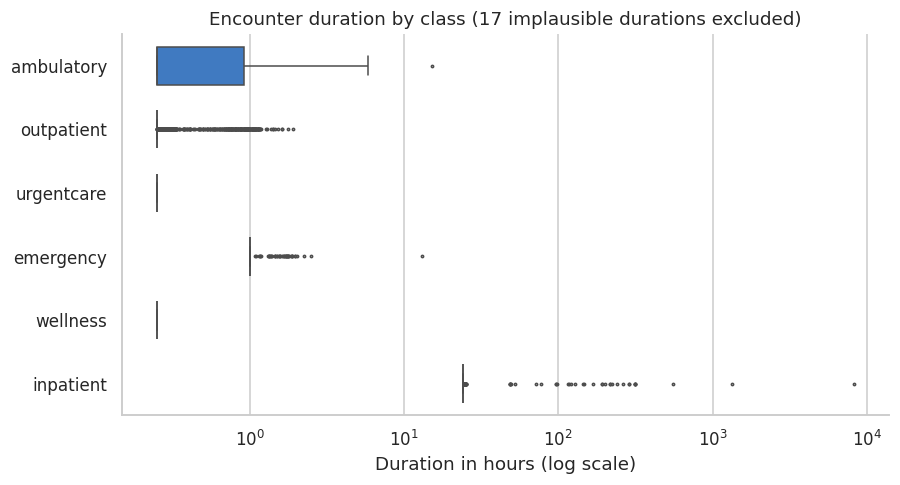

In [31]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=valid, x="duration_h", y="ENCOUNTERCLASS", order=CLASS_ORDER, color=BAR_COLOR,
            log_scale=True, fliersize=1.5, width=0.6, ax=ax)
ax.set(xlabel="Duration in hours (log scale)", ylabel="",
       title=f"Encounter duration by class ({enc['duration_suspect'].sum()} implausible durations excluded)")
save_fig(fig, "05_duration_by_class.png")

The chart confirms Section 3.3: most classes collapse to a single line, meaning one fixed duration. Only ambulatory has a real spread. A few inpatient stays run to weeks or months, the longest about 11 months (8,250 hours).

### 4.6 Duration vs claim cost

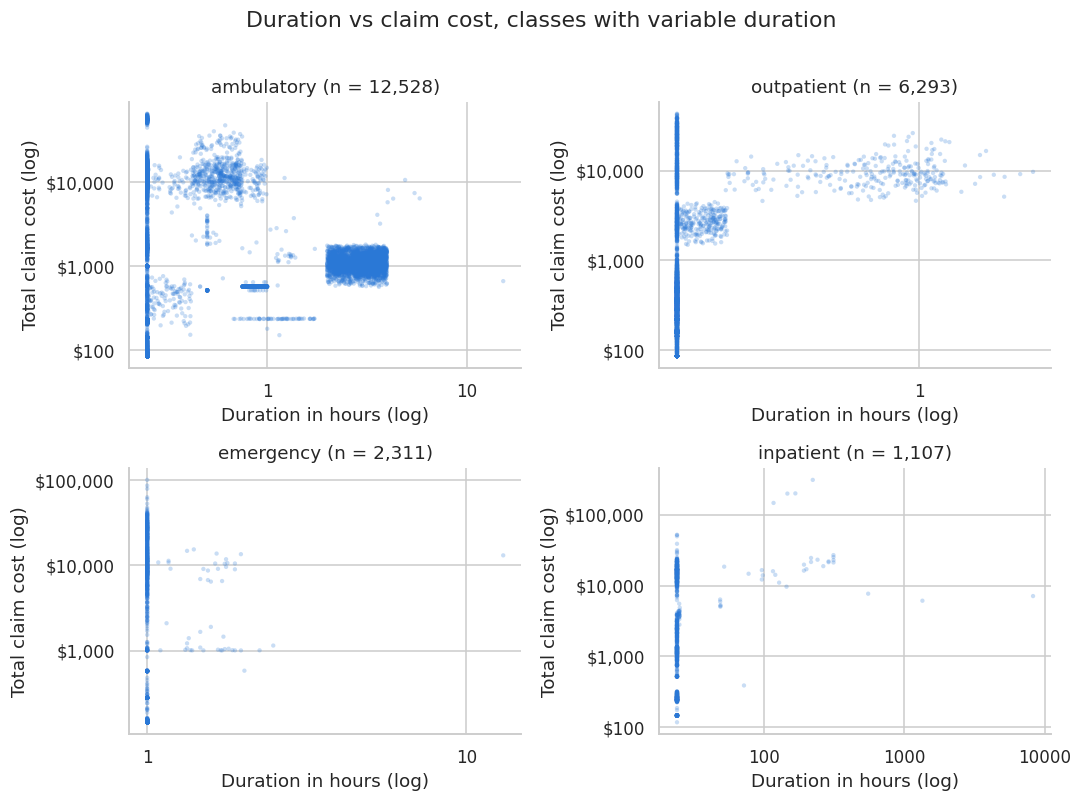

In [32]:
dur_df = enc[~enc["duration_suspect"] & enc["ENCOUNTERCLASS"].isin(VARIABLE_DURATION_CLASSES)]
n_panels = len(VARIABLE_DURATION_CLASSES)
fig, axes = plt.subplots(int(np.ceil(n_panels / 2)), 2, figsize=(10, 3.6 * np.ceil(n_panels / 2)), squeeze=False)
for ax, cls in zip(axes.flat, VARIABLE_DURATION_CLASSES):
    sub = dur_df[(dur_df["ENCOUNTERCLASS"] == cls) & (dur_df["TOTAL_CLAIM_COST"] > 0)]
    ax.scatter(sub["duration_h"], sub["TOTAL_CLAIM_COST"], s=8, alpha=0.25, color=BAR_COLOR, edgecolors="none")
    ax.set(xscale="log", yscale="log", title=f"{cls} (n = {len(sub):,})",
           xlabel="Duration in hours (log)", ylabel="Total claim cost (log)")
    ax.yaxis.set_major_formatter(dollars)
    ax.xaxis.set_major_formatter(plain)
    ax.xaxis.set_minor_formatter(NullFormatter())
for ax in list(axes.flat)[n_panels:]:
    ax.set_visible(False)
fig.suptitle("Duration vs claim cost, classes with variable duration", y=1.01)
fig.tight_layout()
save_fig(fig, "06_duration_vs_cost.png")

- **Ambulatory** encounters form distinct **clusters**: blocks of encounters with the same duration range *and* the same cost band. One example is the block at 2–4 hours costing about $1,000: these are "Encounter for problem (procedure)" visits, with a median of 2.8 hours and $1,041 (see the table in Section 6.1). Each cluster is a *type* of encounter. Any duration–cost association may simply reflect **which type** of encounter it was, not the time spent. Encounter type is therefore a **confounder**, and H2 checks for it.
- **Outpatient:** the few encounters longer than 15 minutes cost more ($2,000–$10,000), but 15-minute encounters already range from $86 to $40,000.
- **Emergency and inpatient:** almost every point sits on one duration (1 hour and 24 hours respectively). The handful of longer inpatient stays do cost more.

### 4.7 Where the cost comes from: procedures

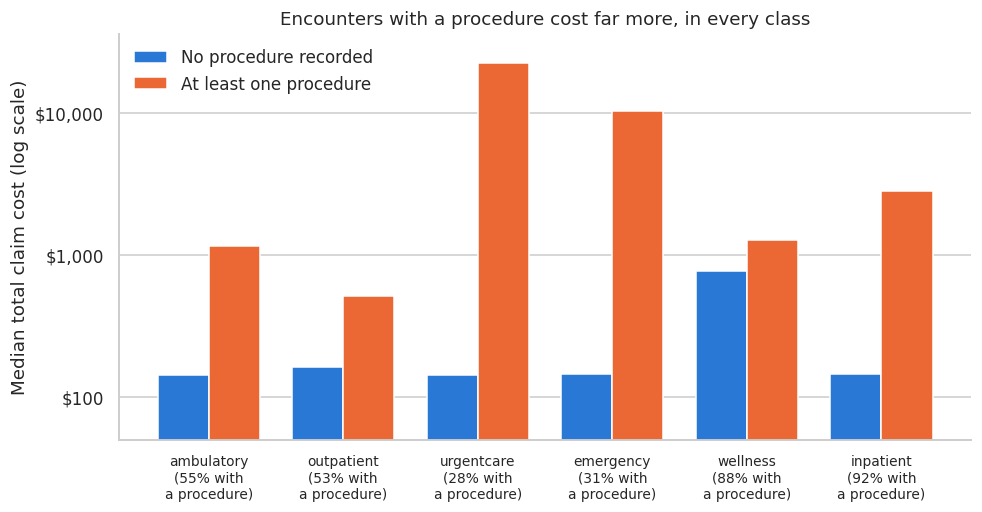

has_procedure,False,True
ENCOUNTERCLASS,,
ambulatory,142.58,"1,165.89"
outpatient,163.40,511.50
urgentcare,142.58,"22,598.02"
emergency,146.18,"10,233.45"
wellness,778.78,"1,278.45"
inpatient,146.18,"2,811.95"


In [33]:
with_proc = enc.groupby(["ENCOUNTERCLASS", "has_procedure"])["TOTAL_CLAIM_COST"].median().unstack().reindex(CLASS_ORDER)
x = np.arange(len(CLASS_ORDER))
width = 0.38
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.bar(x - width / 2, with_proc[False], width, color=SERIES[0], label="No procedure recorded")
ax.bar(x + width / 2, with_proc[True], width, color=SERIES[1], label="At least one procedure")
ax.set_xticks(x, [f"{c}\n({class_summary.loc[c, 'pct_with_procedure']:.0%} with\na procedure)"
                  for c in CLASS_ORDER], fontsize=9)
ax.set_yscale("log")
ax.set_ylim(50, with_proc.max().max() * 1.6)
ax.yaxis.set_major_formatter(dollars)
ax.legend(frameon=False, loc="upper left")
ax.set(ylabel="Median total claim cost (log scale)",
       title="Encounters with a procedure cost far more, in every class")
ax.grid(axis="x", visible=False)
save_fig(fig, "07_cost_with_and_without_procedures.png")
with_proc

In [34]:
# Which procedures appear in the expensive urgent care and emergency encounters?
for cls in ["urgentcare", "emergency"]:
    ids = enc.loc[enc["ENCOUNTERCLASS"] == cls, "Id"]
    top = procedures_raw[procedures_raw["ENCOUNTER"].isin(ids)].groupby("DESCRIPTION")["BASE_COST"].agg(["size", "median"])
    print(f"--- {cls}: most frequent procedures (count, median base cost)")
    print(top.sort_values("size", ascending=False).head(5).to_string(), "\n")

--- urgentcare: most frequent procedures (count, median base cost)
                                                                                 size    median
DESCRIPTION                                                                                    
Electrical cardioversion                                                          792 24,951.00
Catheter ablation of tissue of heart                                              213  9,290.00
Referral to home health care service (procedure)                                   33    431.00
Echocardiography (procedure)                                                        2    980.00
Percutaneous mechanical thrombectomy of portal vein using fluoroscopic guidance     2 17,338.00 

--- emergency: most frequent procedures (count, median base cost)
                               size    median
DESCRIPTION                                  
Electrical cardioversion        159 25,959.00
Bone immobilization             118    431.00
Childbirt

**Procedures explain much of the class pattern.** Without a procedure, the median claim in every class except wellness is just the base cost of about $150. With a procedure, the median urgent care claim is **$22,598** and the median emergency claim is **$10,233**. The procedure list above shows which interventions drive those amounts. Wellness encounters almost always include a bundle of screenings, which explains their consistent cost of around $1,200.

So **encounter class is partly a stand-in for procedure mix**. A cost difference between classes describes *where* cost is recorded, not *why*.

### 4.8 Payer mix by class (potential confounder)

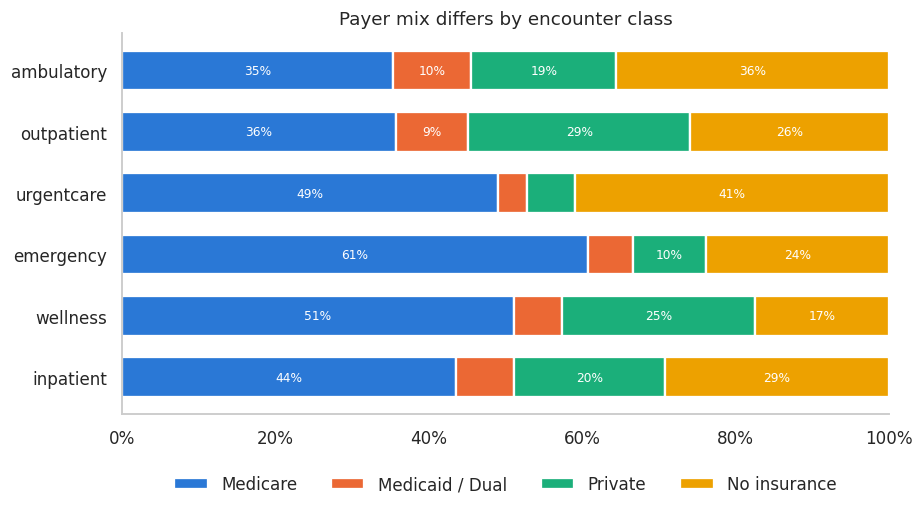

In [35]:
mix = pd.crosstab(enc["ENCOUNTERCLASS"], enc["payer_group"], normalize="index").reindex(CLASS_ORDER)[PAYER_GROUPS]
fig, ax = plt.subplots(figsize=(9, 4.5))
left = np.zeros(len(mix))
for color, group in zip(SERIES, PAYER_GROUPS):
    ax.barh(mix.index, mix[group], left=left, color=color, label=group, edgecolor="white", linewidth=1.5, height=0.65)
    for y, (start, share) in enumerate(zip(left, mix[group])):
        if share >= 0.08:
            ax.text(start + share / 2, y, f"{share:.0%}", ha="center", va="center", fontsize=8, color="white")
    left += mix[group].values
ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False)
ax.set(xlim=(0, 1), title="Payer mix differs by encounter class")
ax.grid(visible=False)
save_fig(fig, "08_payer_mix_by_class.png")

Payer mix differs noticeably by class. **61% of emergency encounters are Medicare**, and **41% of urgent care encounters are uninsured**. If claim amounts depend on the payer, part of any class difference could be a payer difference. Payer is therefore a potential confounder, noted in the limitations.

### 4.9 Encounter volume over time

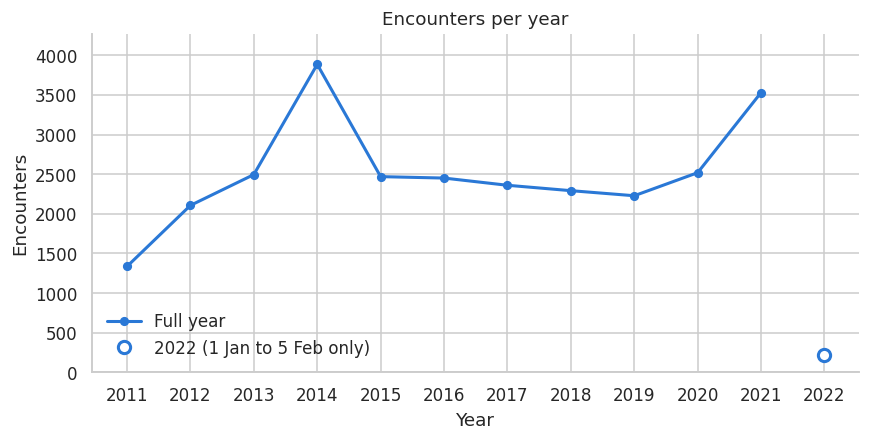

In [36]:
yearly = enc.groupby("year").size()
full_years = yearly[yearly.index < 2022]
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(full_years.index, full_years.values, color=BAR_COLOR, lw=2, marker="o", ms=5, label="Full year")
ax.plot([2022], [yearly[2022]], ls="none", marker="o", ms=8, mfc="white", mec=BAR_COLOR, mew=2,
        label="2022 (1 Jan to 5 Feb only)")
ax.set(xlabel="Year", ylabel="Encounters", ylim=(0, yearly.max() * 1.1), title="Encounters per year")
ax.set_xticks(yearly.index)
ax.legend(frameon=False)
save_fig(fig, "09_encounters_per_year.png")

Volume rose from 2011 to 2014, spiked in **2014 (3,885)**, settled at about 2,300–2,500 a year, and rose again in **2021 (3,530)**. 2022 contains only five weeks of data. The 2014 spike is also the year the implausible-duration records come from (Section 3.2), so it may partly reflect a recording change. That cannot be confirmed from this data.

### 4.10 What the exploratory analysis shows, and what it cannot establish
**Shows:**
- Claim costs are highly skewed and differ in both level and shape between classes.
- Procedures are the main visible driver of high claims.
- Recorded durations are mostly fixed templates.
- A small number of patients generate a large share of encounters.

**Cannot establish:**
- *Why* costs differ: there is no severity, diagnosis-mix or medication data.
- Whether the classes would cost the same for comparable patients (confounding by procedure, payer and age).
- Anything about other hospitals.
- Real-world time spent with patients: durations are templated.

## 5. Hypothesis 1: claim cost differs across encounter classes

**Question:** do recorded total claim costs differ between encounter classes?

- **H₀:** the claim cost distribution is the same in all six classes. A claim from one class is as likely to be higher as lower than a claim from any other class.
- **H₁:** at least one class tends to have higher (or lower) claim costs than the others.
- **Variables:** `TOTAL_CLAIM_COST` (continuous, heavily skewed) and `ENCOUNTERCLASS` (six groups of very unequal size).
- **Significance level:** α = 0.05.

**Method: Kruskal-Wallis H test**, followed by pairwise Mann-Whitney U tests with a Holm correction for the 15 comparisons.

**Why not one-way ANOVA?** ANOVA assumes roughly normal residuals and equal variances. Costs have a skewness of 16 and variances that differ by orders of magnitude between classes (checked below), and group sizes range from 1,135 to 12,537. A log transform would not rescue it, because of the $0 claims and because managers care about typical (median) cost, not the mean of logs.

**Assumptions of Kruskal-Wallis and how they are handled**
1. *Independent observations.* This is **violated** at the encounter level (Section 4.4). The primary test therefore uses **one value per patient per class** (that patient's median claim in the class). The encounter-level test is shown only for comparison.
2. *Ordinal or continuous outcome.* Met.
3. *Similar distribution shapes, needed to read the result as "the medians differ".* **Not met** (Section 4.3). The result is therefore read as *"claims in class A tend to be higher than in class B"* (stochastic dominance). Medians are reported separately with bootstrap confidence intervals.

**Effect sizes:**
- ε² (epsilon-squared) for the overall test: roughly 0.01 small, 0.06 medium, 0.14 large.
- For each pair, the **probability of superiority** P(A > B): the chance that a randomly chosen claim from A exceeds one from B. 0.5 means no difference.

In [37]:
# Why not ANOVA: unequal variances and extreme skew
groups_enc = [enc.loc[enc["ENCOUNTERCLASS"] == c, "TOTAL_CLAIM_COST"].values for c in CLASS_ORDER]
levene = stats.levene(*groups_enc, center="median")
print(f"Brown-Forsythe test for equal variances: W = {levene.statistic:.1f}, p = {levene.pvalue:.2g}")
print("Standard deviation by class:",
      enc.groupby("ENCOUNTERCLASS")["TOTAL_CLAIM_COST"].std().reindex(CLASS_ORDER).round(0).to_dict())
print("Skewness by class:          ",
      enc.groupby("ENCOUNTERCLASS")["TOTAL_CLAIM_COST"].skew().reindex(CLASS_ORDER).round(1).to_dict())

Brown-Forsythe test for equal variances: W = 159.2, p = 2.3e-167
Standard deviation by class: {'ambulatory': 7124.0, 'outpatient': 5717.0, 'urgentcare': 11233.0, 'emergency': 16049.0, 'wellness': 8404.0, 'inpatient': 15017.0}
Skewness by class:           {'ambulatory': 5.0, 'outpatient': 3.8, 'urgentcare': 1.6, 'emergency': 27.5, 'wellness': 2.9, 'inpatient': 11.7}


### 5.1 Helper functions
- `patient_bootstrap` resamples **patients** with replacement and keeps all of each patient's encounters together, so the confidence intervals reflect the fact that encounters from the same patient are related.
- `holm` adjusts p-values for multiple comparisons.

In [38]:
def patient_bootstrap(df, statistic, n_boot=1000, seed=RANDOM_STATE):
    # Resample patients with replacement; each draw keeps all of that patient's rows together
    rng = np.random.default_rng(seed)
    rows_by_patient = list(df.groupby("PATIENT").indices.values())
    results = []
    for _ in range(n_boot):
        picked = rng.integers(0, len(rows_by_patient), len(rows_by_patient))
        sample = df.iloc[np.concatenate([rows_by_patient[i] for i in picked])]
        results.append(statistic(sample))
    return pd.DataFrame(results)


def holm(pvalues):
    # Holm-Bonferroni step-down adjustment
    p = np.asarray(pvalues, dtype=float)
    adjusted = np.empty(len(p))
    running_max = 0.0
    for rank, i in enumerate(np.argsort(p)):
        running_max = max(running_max, (len(p) - rank) * p[i])
        adjusted[i] = min(running_max, 1.0)
    return adjusted

### 5.2 Overall test

In [39]:
# One value per patient per class: that patient's median claim in the class
patient_class_cost = enc.groupby(["PATIENT", "ENCOUNTERCLASS"], as_index=False)["TOTAL_CLAIM_COST"].median()
print("Patients contributing to each class:")
print(patient_class_cost["ENCOUNTERCLASS"].value_counts().reindex(CLASS_ORDER).to_string(), "\n")

def kruskal_summary(df, label):
    groups = [df.loc[df["ENCOUNTERCLASS"] == c, "TOTAL_CLAIM_COST"].values for c in CLASS_ORDER]
    result = stats.kruskal(*groups)
    n = sum(len(g) for g in groups)
    return {"analysis": label, "n": n, "H": result.statistic, "p_value": result.pvalue,
            "epsilon_squared": result.statistic / (n - 1)}

h1_overall = pd.DataFrame([
    kruskal_summary(patient_class_cost, "Patient level (primary)"),
    kruskal_summary(enc, "Encounter level (ignores repeated records)"),
])
h1_overall.style.format({"n": "{:,}", "H": "{:,.1f}", "p_value": "{:.2e}", "epsilon_squared": "{:.3f}"})

Patients contributing to each class:
ENCOUNTERCLASS
ambulatory    695
outpatient    624
urgentcare    247
emergency     465
wellness      209
inpatient     153 



,analysis,n,H,p_value,epsilon_squared
0,Patient level (primary),"2,393",363.0,2.72e-76,0.152
1,Encounter level (ignores repeated records),"27,891","2,025.2",0.00e+00,0.073


### 5.3 Class medians with patient-bootstrap confidence intervals
For comparison, a naive bootstrap that resamples individual encounters is also run. If it gives much narrower intervals, that shows how ignoring repeated records overstates precision.

In [40]:
def class_medians(sample):
    return sample.groupby("ENCOUNTERCLASS")["TOTAL_CLAIM_COST"].median()

boot_patient = patient_bootstrap(enc, class_medians)

rng = np.random.default_rng(RANDOM_STATE)
boot_naive = pd.DataFrame([class_medians(enc.iloc[rng.integers(0, len(enc), len(enc))]) for _ in range(1000)])

median_ci = pd.DataFrame({
    "median": class_medians(enc),
    "ci_low": boot_patient.quantile(0.025),
    "ci_high": boot_patient.quantile(0.975),
    "ci_width_patient": boot_patient.quantile(0.975) - boot_patient.quantile(0.025),
    "ci_width_naive": boot_naive.quantile(0.975) - boot_naive.quantile(0.025),
}).reindex(CLASS_ORDER)
median_ci.to_csv(os.path.join(OUT_DIR, "h1_class_medians_ci.csv"))
median_ci

,median,ci_low,ci_high,ci_width_patient,ci_width_naive
ENCOUNTERCLASS,,,,,
ambulatory,573.98,234.72,800.87,566.15,127.88
outpatient,278.58,278.58,278.58,0.00,0.00
urgentcare,142.58,142.58,278.58,136.00,0.00
emergency,146.18,146.18,212.63,66.45,0.00
wellness,"1,231.44","1,183.93","1,292.00",108.07,56.45
inpatient,"2,355.59","1,199.70","11,028.36","9,828.65",722.37


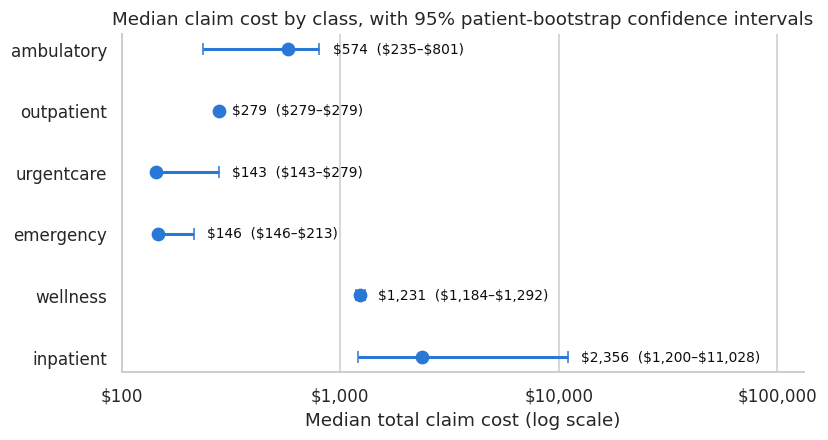

In [41]:
fig, ax = plt.subplots(figsize=(8, 4))
y = np.arange(len(CLASS_ORDER))
ax.errorbar(median_ci["median"], y,
            xerr=[median_ci["median"] - median_ci["ci_low"], median_ci["ci_high"] - median_ci["median"]],
            fmt="o", color=BAR_COLOR, ms=8, capsize=4, lw=2)
for yi, (low, high, med) in enumerate(zip(median_ci["ci_low"], median_ci["ci_high"], median_ci["median"])):
    ax.text(high * 1.15, yi, f"${med:,.0f}  (${low:,.0f}–${high:,.0f})", va="center", fontsize=9, color=INK)
ax.set_yticks(y, CLASS_ORDER)
ax.invert_yaxis()
ax.set_xscale("log")
ax.xaxis.set_major_formatter(dollars)
ax.set_xlim(median_ci["ci_low"].min() * 0.7, median_ci["ci_high"].max() * 12)
ax.set(xlabel="Median total claim cost (log scale)",
       title="Median claim cost by class, with 95% patient-bootstrap confidence intervals")
ax.grid(axis="y", visible=False)
save_fig(fig, "10_h1_class_medians_ci.png")

### 5.4 Pairwise comparisons
Mann-Whitney U tests on the patient-level values, with a Holm adjustment. `prob_a_gt_b` is the probability of superiority P(A > B).

In [42]:
from itertools import combinations

pair_rows = []
for a, b in combinations(CLASS_ORDER, 2):
    xa = patient_class_cost.loc[patient_class_cost["ENCOUNTERCLASS"] == a, "TOTAL_CLAIM_COST"]
    xb = patient_class_cost.loc[patient_class_cost["ENCOUNTERCLASS"] == b, "TOTAL_CLAIM_COST"]
    result = stats.mannwhitneyu(xa, xb, alternative="two-sided")
    pair_rows.append({"class_a": a, "class_b": b, "n_a": len(xa), "n_b": len(xb),
                      "median_a": xa.median(), "median_b": xb.median(),
                      "prob_a_gt_b": result.statistic / (len(xa) * len(xb)), "p_raw": result.pvalue})
h1_pairs = pd.DataFrame(pair_rows)
h1_pairs["p_holm"] = holm(h1_pairs["p_raw"])
h1_pairs["significant"] = h1_pairs["p_holm"] < 0.05
h1_pairs.to_csv(os.path.join(OUT_DIR, "h1_pairwise_tests.csv"), index=False)
h1_pairs.style.format({"median_a": "${:,.0f}", "median_b": "${:,.0f}", "prob_a_gt_b": "{:.2f}",
                       "p_raw": "{:.2e}", "p_holm": "{:.2e}"})

,class_a,class_b,n_a,n_b,median_a,median_b,prob_a_gt_b,p_raw,p_holm,significant
0,ambulatory,outpatient,695,624,$235,$279,0.44,1.30e-04,7.79e-04,True
1,ambulatory,urgentcare,695,247,$235,$279,0.46,9.90e-02,3.96e-01,False
2,ambulatory,emergency,695,465,$235,"$2,758",0.31,3.03e-29,3.63e-28,True
3,ambulatory,wellness,695,209,$235,"$1,138",0.20,5.19e-40,6.75e-39,True
4,ambulatory,inpatient,695,153,$235,"$2,527",0.33,1.07e-11,9.66e-11,True
5,outpatient,urgentcare,624,247,$279,$279,0.54,5.66e-02,2.83e-01,False
6,outpatient,emergency,624,465,$279,"$2,758",0.32,6.26e-26,6.89e-25,True
7,outpatient,wellness,624,209,$279,"$1,138",0.11,5.59e-67,8.38e-66,True
8,outpatient,inpatient,624,153,$279,"$2,527",0.34,1.78e-10,1.42e-09,True
9,urgentcare,emergency,247,465,$279,"$2,758",0.28,3.88e-22,3.88e-21,True


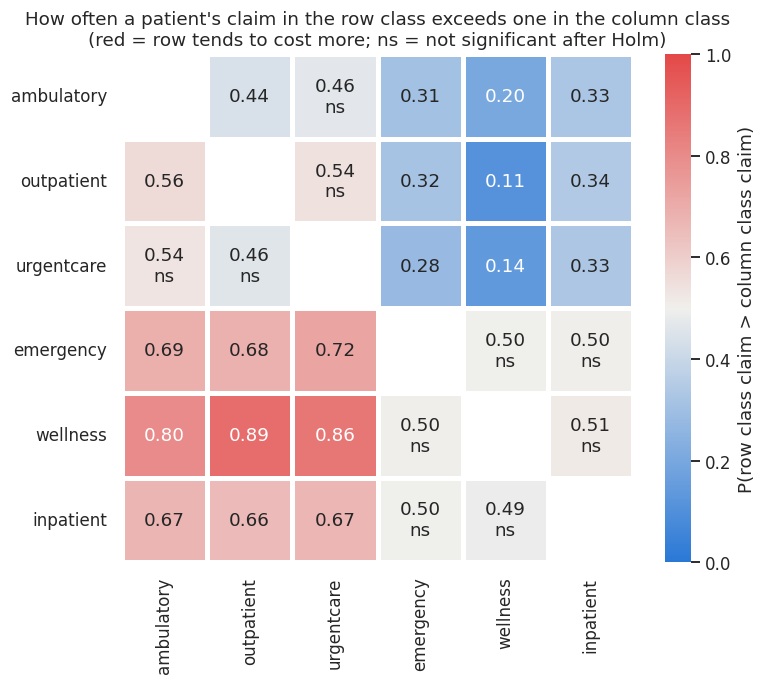

In [43]:
from matplotlib.colors import LinearSegmentedColormap

# Matrix of P(row > column); P(b > a) = 1 - P(a > b) because ties count as half
superiority = pd.DataFrame(np.nan, index=CLASS_ORDER, columns=CLASS_ORDER)
significant = pd.DataFrame(False, index=CLASS_ORDER, columns=CLASS_ORDER)
for row in h1_pairs.itertuples():
    superiority.loc[row.class_a, row.class_b] = row.prob_a_gt_b
    superiority.loc[row.class_b, row.class_a] = 1 - row.prob_a_gt_b
    significant.loc[row.class_a, row.class_b] = significant.loc[row.class_b, row.class_a] = row.significant

labels = superiority.map(lambda v: "" if np.isnan(v) else f"{v:.2f}") + significant.map(lambda s: "" if s else "\nns")
for c in CLASS_ORDER:
    labels.loc[c, c] = ""
diverging = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(superiority, annot=labels, fmt="", cmap=diverging, vmin=0, vmax=1, center=0.5,
            linewidths=2, linecolor="white", cbar_kws={"label": "P(row class claim > column class claim)"}, ax=ax)
ax.grid(False)
ax.set(xlabel="", ylabel="",
       title="How often a patient's claim in the row class exceeds one in the column class\n(red = row tends to cost more; ns = not significant after Holm)")
save_fig(fig, "11_h1_pairwise_superiority.png")

### 5.5 Frequent users change the picture
The encounter-level and patient-level medians disagree sharply for some classes, most of all emergency: the typical emergency *encounter* costs $146, but the typical emergency *patient* has a median claim of about $2,758. The table below compares the 5% most frequent users of each class with everyone else.

In [44]:
frequent_rows = []
for cls in CLASS_ORDER:
    sub = enc[enc["ENCOUNTERCLASS"] == cls]
    visits = sub.groupby("PATIENT").size().sort_values(ascending=False, kind="stable")
    k = max(1, round(len(visits) * 0.05))
    frequent = sub["PATIENT"].isin(visits.index[:k])
    frequent_rows.append({
        "class": cls, "patients": len(visits), "frequent users (top 5%)": k,
        "share of encounters from frequent users": frequent.mean(),
        "median claim, frequent users": sub.loc[frequent, "TOTAL_CLAIM_COST"].median(),
        "median claim, other patients": sub.loc[~frequent, "TOTAL_CLAIM_COST"].median(),
        "encounter-level median": sub["TOTAL_CLAIM_COST"].median(),
        "patient-level median": patient_class_cost.loc[patient_class_cost["ENCOUNTERCLASS"] == cls, "TOTAL_CLAIM_COST"].median(),
    })
frequent_users = pd.DataFrame(frequent_rows)
frequent_users.to_csv(os.path.join(OUT_DIR, "frequent_user_effect.csv"), index=False)
frequent_users.style.format({"share of encounters from frequent users": "{:.0%}",
                             "median claim, frequent users": "${:,.0f}", "median claim, other patients": "${:,.0f}",
                             "encounter-level median": "${:,.0f}", "patient-level median": "${:,.0f}"})

,class,patients,frequent users (top 5%),share of encounters from frequent users,"median claim, frequent users","median claim, other patients",encounter-level median,patient-level median
0,ambulatory,695,35,45%,$875,$235,$574,$235
1,outpatient,624,31,36%,$326,$279,$279,$279
2,urgentcare,247,12,59%,$143,$143,$143,$279
3,emergency,465,23,62%,$146,"$1,066",$146,"$2,758"
4,wellness,209,10,6%,"$1,192","$1,232","$1,231","$1,138"
5,inpatient,153,8,37%,"$9,916","$1,982","$2,356","$2,527"


### 5.6 Interpretation of Hypothesis 1

**Result.** The patient-level Kruskal-Wallis test gives **H = 363.0, p ≈ 3 × 10⁻⁷⁶, ε² = 0.15** (a large effect). **H₀ is rejected.** The encounter-level test agrees (ε² = 0.07), so success criterion 2 is met.

**The classes fall into two cost tiers** (patient-level medians):

| Tier | Classes | Typical claim per patient |
|---|---|---|
| Lower | ambulatory, outpatient, urgent care | $235–$279 |
| Higher | emergency, wellness, inpatient | $1,138–$2,758 |

- Every lower-vs-higher comparison is significant after the Holm correction, with a probability of superiority between 0.66 and 0.89. For example, a patient's wellness claim exceeds their outpatient claim **89%** of the time.
- Inside each tier the differences are small and mostly not significant. The one exception is ambulatory vs outpatient (P = 0.44, a small effect).

**In plain language:** the type of encounter makes a large difference to the claim amount. Emergency, wellness and inpatient encounters reliably cost more than ambulatory, outpatient and urgent care encounters.

**Counting visits vs counting patients gives different answers.** About 5% of emergency patients generate about 60% of emergency encounters, and their visits are cheap (around the $146 base cost). Everyone else's emergency visits have a median of about $1,066. The encounter-level median is therefore a picture of a few frequent attenders, not of a typical emergency patient. In ambulatory care it is the reverse: the most frequent users have the more expensive visits.

**Ignoring repeated records overstates precision.** The patient-bootstrap intervals are about **4×** wider than a naive encounter bootstrap for ambulatory and about **14×** wider for inpatient (Section 5.3). Some intervals have zero width (outpatient, $279–$279) because a large share of claims are exactly $278.58, a fixed template price.

**Practical significance:** the effect is large enough to matter for budgeting. A single hospital-wide "average cost per encounter" hides a roughly tenfold difference between tiers, and the answer changes depending on whether you count visits or patients.

**Limitations of this result:**
- Patient-level groups overlap: the same patient can appear in several classes, so they are not fully independent.
- Class is partly a stand-in for **procedure mix** (Section 4.7).
- Payer and age differences between classes were not adjusted for.
- Claim amounts are not the true cost of care.

## 6. Hypothesis 2: longer encounters cost more within a class

**Question:** within an encounter class, are longer encounters associated with higher claim costs?

- **H₀:** within the class, there is no monotonic association between duration and total claim cost (Spearman ρ = 0).
- **H₁:** there is a monotonic association (ρ ≠ 0). The test is two-sided, because longer encounters could also be the cheaper ones.
- **Variables:** `duration_h` (from `STOP − START`) and `TOTAL_CLAIM_COST`.
- **Data:** the four classes whose duration varies (ambulatory, outpatient, emergency, inpatient), excluding the 17 `duration_suspect` encounters.
- **Significance level:** α = 0.05, with a Holm adjustment across the four classes.

**Why test each class separately?** Pooling all classes would mostly measure *class* differences: inpatient stays are both long and expensive. A strong pooled correlation could then appear even if duration made no difference within any class (Simpson's paradox).

**Method: Spearman's rank correlation.** Both variables are skewed with extreme values, and the relationship need not be linear, so Pearson's correlation is not appropriate.

**Assumptions and how they are handled**
1. *Independent pairs.* This is **violated** (repeated records). Confidence intervals come from the **patient bootstrap**, and a **patient-level** version (each patient's median duration vs median cost) is reported as a sensitivity check.
2. *Monotonic relationship.* This was checked visually in Section 4.6.
3. *Ordinal or continuous variables.* Met. **Ties** are handled with average ranks, but 92–98% of encounters in three classes share one duration. ρ is then driven by the small minority of non-standard encounters, so the share of such encounters is reported next to ρ.

**Confounding check.** Section 4.6 showed that ambulatory encounters cluster by encounter *type*. A **within-type** rank correlation is also computed: ranks are centred within each encounter description, so the correlation only uses variation *inside* the same type of encounter.

In [45]:
def spearman_rho(sample):
    return stats.spearmanr(sample["duration_h"], sample["TOTAL_CLAIM_COST"]).statistic


def within_type_rho(sample):
    # Rank both variables, centre the ranks within each encounter description, then correlate
    ranks = sample[["duration_h", "TOTAL_CLAIM_COST"]].rank()
    centred = ranks - ranks.groupby(sample["DESCRIPTION"].values).transform("mean")
    return centred["duration_h"].corr(centred["TOTAL_CLAIM_COST"])


h2_rows = []
for cls in VARIABLE_DURATION_CLASSES:
    sub = dur_df[dur_df["ENCOUNTERCLASS"] == cls]
    overall = stats.spearmanr(sub["duration_h"], sub["TOTAL_CLAIM_COST"])
    per_patient_medians = sub.groupby("PATIENT")[["duration_h", "TOTAL_CLAIM_COST"]].median()
    patient_level = stats.spearmanr(per_patient_medians["duration_h"], per_patient_medians["TOTAL_CLAIM_COST"])
    boot = patient_bootstrap(sub, lambda s: {"rho": spearman_rho(s), "rho_within": within_type_rho(s)})
    h2_rows.append({
        "class": cls, "encounters": len(sub), "patients": sub["PATIENT"].nunique(),
        "share_non_standard_duration": 1 - share_at_mode(sub["duration_h"]),
        "rho": overall.statistic, "rho_ci_low": boot["rho"].quantile(0.025), "rho_ci_high": boot["rho"].quantile(0.975),
        "p_raw": overall.pvalue,
        "rho_within_type": within_type_rho(sub),
        "within_ci_low": boot["rho_within"].quantile(0.025), "within_ci_high": boot["rho_within"].quantile(0.975),
        "rho_patient_level": patient_level.statistic, "p_patient_level": patient_level.pvalue,
    })
h2_results = pd.DataFrame(h2_rows)
h2_results["p_holm"] = holm(h2_results["p_raw"])
h2_results.to_csv(os.path.join(OUT_DIR, "h2_duration_cost_correlations.csv"), index=False)
h2_results.round(3)

,class,encounters,patients,share_non_standard_duration,rho,rho_ci_low,rho_ci_high,p_raw,rho_within_type,within_ci_low,within_ci_high,rho_patient_level,p_patient_level,p_holm
0,ambulatory,12532,695,0.37,0.48,0.39,0.54,0.00,0.53,0.46,0.58,0.45,0.00,0.00
1,outpatient,6293,623,0.08,0.40,0.34,0.46,0.00,0.17,0.13,0.21,0.29,0.00,0.00
2,emergency,2317,464,0.02,0.16,0.07,0.23,0.00,0.06,0.03,0.13,0.08,0.09,0.00
3,inpatient,1135,153,0.05,0.17,0.07,0.29,0.00,0.24,0.14,0.37,0.46,0.00,0.00


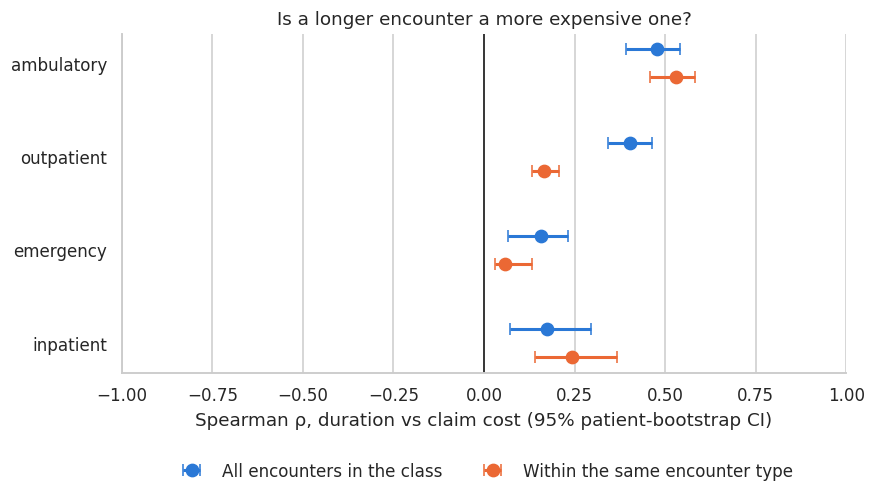

In [46]:
fig, ax = plt.subplots(figsize=(8.5, 4))
y = np.arange(len(h2_results))
offset = 0.15
for shift, col, low, high, color, label in [
        (-offset, "rho", "rho_ci_low", "rho_ci_high", SERIES[0], "All encounters in the class"),
        (offset, "rho_within_type", "within_ci_low", "within_ci_high", SERIES[1], "Within the same encounter type")]:
    ax.errorbar(h2_results[col], y + shift,
                xerr=[h2_results[col] - h2_results[low], h2_results[high] - h2_results[col]],
                fmt="o", ms=8, capsize=4, lw=2, color=color, label=label)
ax.axvline(0, color=INK, lw=1)
ax.set_yticks(y, h2_results["class"])
ax.invert_yaxis()
ax.set(xlim=(-1, 1), xlabel="Spearman ρ, duration vs claim cost (95% patient-bootstrap CI)",
       title="Is a longer encounter a more expensive one?")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, frameon=False)
ax.grid(axis="y", visible=False)
save_fig(fig, "12_h2_duration_cost_correlation.png")

### 6.1 Confounding check in detail: ambulatory encounter types

In [47]:
amb = dur_df[dur_df["ENCOUNTERCLASS"] == "ambulatory"]
type_rows = []
for desc, g in amb.groupby("DESCRIPTION"):
    if len(g) >= 100:
        varies = g["duration_h"].round(3).nunique() > 1
        result = stats.spearmanr(g["duration_h"], g["TOTAL_CLAIM_COST"]) if varies else None
        type_rows.append({"encounter type": desc, "encounters": len(g),
                          "median duration (h)": g["duration_h"].median(),
                          "median claim": g["TOTAL_CLAIM_COST"].median(),
                          "rho": result.statistic if varies else np.nan,
                          "p_value": result.pvalue if varies else np.nan})
ambulatory_types = pd.DataFrame(type_rows).sort_values("encounters", ascending=False)
ambulatory_types.round(3)

,encounter type,encounters,median duration (h),median claim,rho,p_value
2,Encounter for problem (procedure),3135,2.83,"1,041.12",0.31,0.00
3,Encounter for symptom,1814,0.25,85.55,0.38,0.00
4,Follow-up encounter,1565,0.25,234.72,NaN,NaN
12,Telemedicine consultation with patient,1548,0.25,142.58,NaN,NaN
7,Patient encounter procedure (procedure),1026,0.87,573.98,-0.31,0.00
11,Prenatal visit,1026,0.25,"11,685.67",NaN,NaN
0,Encounter for 'check-up',678,0.47,"9,682.54",0.67,0.00
1,Encounter for problem,325,0.25,"1,456.60",0.20,0.00
9,Postoperative follow-up visit (procedure),290,0.25,142.58,NaN,NaN
5,Follow-up encounter (procedure),258,0.25,215.49,0.52,0.00


### 6.2 Interpretation of Hypothesis 2

| Class | ρ, all encounters (95% CI) | ρ, within encounter type | ρ, patient level | Conclusion |
|---|---|---|---|---|
| ambulatory | **0.48** (0.39 to 0.54) | **0.53** (0.46 to 0.58) | 0.45 | Moderate positive association that **survives** the confounding check |
| outpatient | 0.40 (0.34 to 0.46) | 0.17 (0.13 to 0.21) | 0.29 | Mostly explained by **encounter type**; weak within a type |
| emergency | 0.16 (0.07 to 0.23) | 0.06 (0.03 to 0.13) | 0.08 (p = 0.09) | **Not established**: the patient-level test is not significant, and only 2% of encounters have a non-standard duration |
| inpatient | 0.17 (0.07 to 0.29) | 0.24 (0.14 to 0.37) | 0.46 | Weak positive association, driven by the ~5% of stays longer than the standard 24 hours |

**H₀ is rejected** for ambulatory, outpatient and inpatient encounters. It is **not rejected** for emergency, because the encounter-level and patient-level results disagree (success criterion 2).

**In plain language:**
- In **ambulatory** care, longer visits do tend to cost more, even when comparing visits of the same type.
- **Outpatient:** longer visits look more expensive mainly because the longer *types* of visit are the more expensive types.
- **Emergency:** duration tells us essentially nothing about cost.
- **Inpatient:** only the rare long stays stand out as more expensive.

**Within ambulatory, the pattern is not uniform** (Section 6.1). It is strong for check-ups (ρ = 0.67) and procedure follow-ups (0.52), weaker for problem visits (0.31), and **negative** for "Patient encounter procedure" (−0.31). Many common types, such as telemedicine, prenatal and office visits, have a single fixed duration, so duration cannot explain their cost at all.

**Practical significance:**
- Even the strongest correlation (ρ ≈ 0.5) means duration ranks explain only about a quarter of the variation in cost ranks.
- Recorded durations are mostly fixed templates, so "duration" here is largely another attribute of the encounter type, not time actually spent. Duration is therefore a **weak planning proxy for cost**, useful only for ambulatory care.
- Nothing here shows that **shortening** encounters would reduce cost. This is an association, not a cause.

## 7. Validation

### 7.1 Sanity tests of the analysis functions
Small hand-checkable cases confirm that the helper functions do what the analysis relies on.

In [48]:
rng_test = np.random.default_rng(0)

# 1. Holm adjustment matches a hand-worked example
assert np.allclose(holm([0.01, 0.04, 0.03]), [0.03, 0.06, 0.06])

# 2. Probability of superiority: a entirely below b gives 0, identical samples give 0.5
assert stats.mannwhitneyu([1, 2], [3, 4]).statistic / 4 == 0.0
assert stats.mannwhitneyu([5, 5], [5, 5]).statistic / 4 == 0.5

# 3. The patient bootstrap never splits a patient: each patient appears with all their rows, a whole number of times
toy = pd.DataFrame({"PATIENT": ["a", "a", "a", "b", "c", "c"], "x": range(6)})
original_rows = toy.groupby("PATIENT").size()
draws = patient_bootstrap(toy, lambda s: s.groupby("PATIENT").size() / original_rows, n_boot=200)
assert np.allclose(draws.fillna(0) % 1, 0)

# 4. The within-type correlation removes a purely between-type pattern
toy2 = pd.DataFrame({"DESCRIPTION": ["short"] * 50 + ["long"] * 50,
                     "duration_h": np.r_[rng_test.uniform(0, 1, 50), rng_test.uniform(5, 6, 50)],
                     "TOTAL_CLAIM_COST": np.r_[rng_test.uniform(100, 200, 50), rng_test.uniform(1000, 2000, 50)]})
assert spearman_rho(toy2) > 0.6 and abs(within_type_rho(toy2)) < 0.3

# 5. Kruskal-Wallis epsilon-squared is between 0 and 1
assert h1_overall["epsilon_squared"].between(0, 1).all()

print("All sanity tests passed.")

All sanity tests passed.


### 7.2 Encounter level vs patient level: do the conclusions agree?
A conclusion is only stated when both levels agree (success criterion 2). For H2, both sets of p-values are Holm-adjusted across the four classes.

In [49]:
agreement = pd.DataFrame(
    [{"test": "H1: cost differs across classes",
      "encounter-level p": h1_overall.loc[1, "p_value"], "patient-level p": h1_overall.loc[0, "p_value"]}]
    + [{"test": f"H2: duration vs cost, {row['class']}", "encounter-level p": row["p_holm"], "patient-level p": p_pl}
       for (_, row), p_pl in zip(h2_results.iterrows(), holm(h2_results["p_patient_level"]))])
enc_sig = agreement["encounter-level p"] < 0.05
pat_sig = agreement["patient-level p"] < 0.05
agreement["conclusion"] = np.select([enc_sig & pat_sig, enc_sig ^ pat_sig],
                                    ["Reject H0", "Not established (levels disagree)"], default="Do not reject H0")
agreement.style.format({"encounter-level p": "{:.2e}", "patient-level p": "{:.2e}"})

,test,encounter-level p,patient-level p,conclusion
0,H1: cost differs across classes,0.00e+00,2.72e-76,Reject H0
1,"H2: duration vs cost, ambulatory",0.00e+00,9.48e-36,Reject H0
2,"H2: duration vs cost, outpatient",5.32e-242,6.46e-13,Reject H0
3,"H2: duration vs cost, emergency",7.73e-14,8.64e-02,Not established (levels disagree)
4,"H2: duration vs cost, inpatient",4.09e-09,4.22e-09,Reject H0


### 7.3 Independent reconciliation
The key figures are exported below. `validation/independent_check.py` recomputes them from the raw CSVs **without pandas, NumPy or SciPy**, using only Python's standard library: its own CSV parsing, medians, tie-corrected Kruskal-Wallis and Spearman correlation. It then compares the two sets of figures. The result is recorded in the README (success criterion 1).

This cross-check has caught two real problems, both in the "total = base + procedures" count (Section 3.4):
1. **Wrong tolerance type.** The first version reported 34.4%, but the independent count was 30.4%. The cause was `np.isclose`'s default *relative* tolerance, which treated a $40,000 claim as "equal" even when it was up to 40 cents off. Fixed by setting `rtol=0`.
2. **Tolerance on the boundary.** The next run differed by one encounter (8,492 vs 8,493). 124 claims are exactly **one cent** off (source rounding), and a tolerance of exactly $0.01 left floating-point noise to decide whether each one counted. The two implementations subtract in a different order, so one claim fell on opposite sides. "Equal" is now defined as equal to the cent (tolerance $0.005) in both, which puts no value near the boundary.

In [50]:
key_figures = {}
for cls in CLASS_ORDER:
    key_figures[f"encounters_{cls}"] = class_summary.loc[cls, "encounters"]
    key_figures[f"median_claim_{cls}"] = class_summary.loc[cls, "median_cost"]
    key_figures[f"patient_level_median_{cls}"] = frequent_users.set_index("class").loc[cls, "patient-level median"]
key_figures["encounters_total"] = len(enc)
key_figures["encounters_over_24h"] = int((enc["duration_h"] > 24).sum())
key_figures["duration_suspect"] = int(enc["duration_suspect"].sum())
key_figures["zero_claim_encounters"] = int(zero_claim.sum())
key_figures["total_equals_base_plus_procedures"] = int(base_plus_proc.sum())
key_figures["h1_kruskal_H_patient_level"] = h1_overall.loc[0, "H"]
key_figures["h1_kruskal_H_encounter_level"] = h1_overall.loc[1, "H"]
for _, row in h2_results.iterrows():
    key_figures[f"h2_rho_{row['class']}"] = row["rho"]

key_figures = pd.Series(key_figures, name="value").astype(float)
key_figures.to_csv(os.path.join(OUT_DIR, "key_figures.csv"), index_label="figure")
key_figures.to_frame()

,value
encounters_ambulatory,"12,537.00"
median_claim_ambulatory,573.98
patient_level_median_ambulatory,234.72
encounters_outpatient,"6,300.00"
median_claim_outpatient,278.58
patient_level_median_outpatient,278.58
encounters_urgentcare,"3,666.00"
median_claim_urgentcare,142.58
patient_level_median_urgentcare,278.58
encounters_emergency,"2,322.00"


### 7.4 Privacy check
No exported file may contain an identifying patient column or a patient ID (success criterion 4).

In [51]:
IDENTIFYING = {"FIRST", "LAST", "MIDDLE", "PREFIX", "SUFFIX", "MAIDEN", "ADDRESS", "BIRTHPLACE",
               "CITY", "COUNTY", "ZIP", "LAT", "LON", "PATIENT"}
patient_ids = set(patients["Id"])
for fname in sorted(os.listdir(OUT_DIR)):
    path = os.path.join(OUT_DIR, fname)
    columns = {c.upper() for c in pd.read_csv(path, nrows=0).columns}
    with open(path, encoding="utf-8") as fh:
        text = fh.read()
    assert not columns & IDENTIFYING, f"{fname} has identifying columns: {columns & IDENTIFYING}"
    assert not any(pid in text for pid in patient_ids), f"{fname} contains a patient ID"
    print(f"OK  {fname}")
print("No identifying fields or patient IDs in any exported file.")

OK  class_cost_summary.csv
OK  data_quality_summary.csv
OK  frequent_user_effect.csv
OK  h1_class_medians_ci.csv
OK  h1_pairwise_tests.csv
OK  h2_duration_cost_correlations.csv
OK  key_figures.csv
No identifying fields or patient IDs in any exported file.


The notebook itself and the report are published too, so `validation/privacy_check.py` scans them (and every exported file) for any patient ID, name or address from the raw data before anything is pushed.

## 8. Limitations

- **Repeated records.** 974 patients produce 27,891 encounters, and 10 patients produce 21% of them. Encounter-level tests overstate the evidence, so the analysis uses patient-level values and a patient bootstrap. Even then, a patient can appear in several classes, so the H1 groups are not fully independent.
- **Unequal group sizes.** Classes range from 1,135 to 12,537 encounters (153 to 695 patients). Rank-based tests cope with this, but estimates for the small classes (inpatient, wellness) are less precise, as their wide intervals show.
- **Missing and unsupplied information.**
  - About 70% of each claim total cannot be traced to the supplied tables: medication and immunisation line items are absent.
  - There is no diagnosis severity, so we cannot say *why* costs differ.
  - Reason codes are only present when an encounter targeted a condition.
- **Data-recording problems.**
  - Durations are mostly fixed templates.
  - 17 durations are impossible (kept for cost, excluded from H2).
  - The 2014 volume spike coincides with the bad duration records.
  - Some claims are fixed template prices, which produces zero-width confidence intervals.
- **Confounding.** Encounter class is entangled with procedure mix, payer mix (61% Medicare in emergency vs 35% in ambulatory) and age (medians 70–84 by class). None of these were adjusted for, so class differences are **descriptive, not explanatory**. For H2, encounter type was controlled; payer and age were not.
- **Limited coverage.**
  - One hospital.
  - An elderly adult population (median age about 80).
  - 2022 is only five weeks long.
  - The data appears to be synthetic, so results may reflect the generator's rules and should not be generalised.
- **Claim cost is not cost of care.** `TOTAL_CLAIM_COST` is a recorded claim amount. It is not what the hospital spent or what was paid.
- **Association is not causation.** H1 shows that classes *differ* in recorded cost, not that the class *causes* the cost. H2 shows that longer ambulatory visits *tend to* cost more, not that shortening them would save money. A causal claim would need a design that controls for patient need, such as a comparison of similar patients or an intervention study.
- **Multiple testing.** Fifteen pairwise H1 tests and four H2 tests were run; both families were Holm-adjusted.

## 9. Findings and Recommendations

### Key findings
1. **Claim costs are extremely skewed.** The mean ($3,640) is 13 times the median ($279). Averages misrepresent typical cost.
2. **Encounter class has a large effect on cost** (ε² = 0.15). Emergency, wellness and inpatient claims are reliably higher than ambulatory, outpatient and urgent care claims.
3. **Procedures drive the high claims.** Urgent care claims with a procedure have a median of $22,598, against $143 without one. Urgent care is 13% of encounters but 23% of total claim cost.
4. **A few patients dominate volume.** 5% of emergency patients generate about 60% of emergency encounters, and 10 patients generate 21% of all encounters. Per-encounter and per-patient views of cost differ sharply.
5. **Duration is a weak cost signal.** There is a moderate association within ambulatory care (ρ ≈ 0.5 even within encounter type), little or none in the other classes, and recorded durations are mostly templates.

### Recommendations
These are operational recommendations based on recorded claim data. None is a clinical recommendation.

**1. Set cost KPIs and budgets per encounter class, using medians and percentiles, and split by whether a procedure was performed.**
- *Finding:* findings 1–3.
- *Action:* replace the hospital-wide "average cost per encounter" with, for each class: median claim, 90th percentile and share of encounters with a procedure. Track urgent care and emergency as two streams (with and without a procedure).
- *Benefit:* budgets and variance reviews are no longer distorted by a small number of very large claims, and cost reviews focus on where the money is (for example, procedure-heavy urgent care).
- *Limitation / information needed:* claim amounts are not actual costs; medication line items would explain the remaining ~70% of claim value.

**2. Report both "per encounter" and "per patient" figures, and review the frequent-attender pattern.**
- *Finding:* finding 4.
- *Action:* add per-patient metrics alongside per-encounter metrics in operational reporting. Ask the operations team, with clinical colleagues, to review whether the many low-cost repeat emergency visits by a small group of patients could be scheduled in a more suitable setting.
- *Benefit:* a truer picture of demand and capacity use, and a possible reduction in emergency-department load.
- *Limitation / information needed:* there is no diagnosis or severity data, so this analysis cannot judge whether those visits were clinically necessary. That decision belongs to clinicians.

**3. Do not use recorded duration as a cost driver for planning (except, cautiously, ambulatory care), and fix how encounter times are captured.**
- *Finding:* finding 5; 17 impossible durations, all from 2014 for ambulatory/outpatient; template durations.
- *Action:* validate `STOP` times at data entry (for example, reject non-inpatient encounters over 24 hours), and record actual start and end times rather than defaults. Until then, plan capacity and cost on encounter type and procedure mix.
- *Benefit:* reliable length-of-stay and throughput metrics, and planning assumptions that match the data.
- *Limitation / information needed:* it is not known how the source system sets default durations; the system owners need to confirm this.

**4. Extend the data before drawing explanatory conclusions.**
- *Finding:* the confounding and coverage limitations in Section 8.
- *Action:* request medication/immunisation line items, diagnosis severity and data from more than one site, then re-run the analysis adjusting for payer and age.
- *Benefit:* moves from describing cost differences to explaining them.
- *Limitation / information needed:* requires data-sharing approval and privacy review.

### Success criteria scorecard

| # | Criterion | Status |
|---|---|---|
| 1 | Key figures reconcile with an independent, pandas-free recalculation | Run `validation/independent_check.py` after this notebook; result recorded in the README |
| 2 | Conclusions stated only when encounter- and patient-level results agree | Met (Section 7.2): H2 for emergency left "not established" |
| 3 | Effect sizes with 95% patient-bootstrap CIs for every hypothesis | Met: ε² and probability of superiority (H1), ρ with CIs (H2) |
| 4 | No identifying patient information in any output | Met: automated check in Section 7.4 |
| 5 | Reproducible top-to-bottom run with fixed seed | Met: fixed `RANDOM_STATE`; see README |

In [52]:
# Download the charts and result tables as one zip (Colab); locally they are already in the folders
import zipfile

archive = "week3_outputs.zip"
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as zf:
    for folder in (VIZ_DIR, OUT_DIR):
        for fname in sorted(os.listdir(folder)):
            zf.write(os.path.join(folder, fname))
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    print(f"Saved {archive} next to the notebook.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>